# Installing required libraries

In [1]:
!pip install numpy pandas matplotlib seaborn opencv-python tensorflow keras scikit-learn scipy tabulate tf-keras-vis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.1 MB/s eta 0:00:00


# Path to dataset

In [2]:
PROD_DATASET_PATH = "/kaggle/input/fruits-dataset-for-fruit-disease-classification"

# Import balanced dataset from all data

In [3]:
import os
import shutil
import random
try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm


def create_balanced_dev_dataset(prod_dataset_path, dev_dataset_path, images_per_class=100):
    """
    Create a balanced development dataset by copying a fixed number of images from each class.
    
    Args:
        prod_dataset_path: Path to the production dataset
        dev_dataset_path: Path to create the development dataset
        images_per_class: Number of images to include per class
    """
    # Create base directory for development dataset if it doesn't exist
    if not os.path.exists(dev_dataset_path):
        os.makedirs(dev_dataset_path)
        print(f"Created development dataset directory: {dev_dataset_path}")
    else:
        print(f"Development dataset directory already exists: {dev_dataset_path}")
        if input("Continue and potentially overwrite files? (y/n): ").lower() != 'y':
            print("Operation cancelled.")
            return
    
    # Get all fruit categories
    fruits = [fruit for fruit in os.listdir(prod_dataset_path) 
              if os.path.isdir(os.path.join(prod_dataset_path, fruit))]
    
    print(f"Found {len(fruits)} fruit categories in production dataset")
    
    # Track statistics
    total_copied = 0
    class_count = 0
    
    # Process each fruit category
    for fruit in tqdm(fruits, desc="Processing fruit categories"):
        fruit_prod_path = os.path.join(prod_dataset_path, fruit)
        fruit_dev_path = os.path.join(dev_dataset_path, fruit)
        
        # Create fruit directory in dev dataset
        if not os.path.exists(fruit_dev_path):
            os.makedirs(fruit_dev_path)
        
        # Get all class folders for this fruit
        classes = [cls for cls in os.listdir(fruit_prod_path) 
                  if os.path.isdir(os.path.join(fruit_prod_path, cls))]
        
        # Process each class
        for cls in tqdm(classes, desc=f"Processing classes in {fruit}", leave=False):
            class_count += 1
            cls_prod_path = os.path.join(fruit_prod_path, cls)
            cls_dev_path = os.path.join(fruit_dev_path, cls)
            
            # Create class directory in dev dataset
            if not os.path.exists(cls_dev_path):
                os.makedirs(cls_dev_path)
            
            # Get all image files in the class
            image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
            image_files = [f for f in os.listdir(cls_prod_path) 
                         if os.path.isfile(os.path.join(cls_prod_path, f)) and 
                         os.path.splitext(f.lower())[1] in image_extensions]
            
            # Select images to copy (either all if less than target, or random sample)
            if len(image_files) <= images_per_class:
                selected_images = image_files
                print(f"  Warning: Class {cls} has only {len(image_files)} images, copying all")
            else:
                selected_images = random.sample(image_files, images_per_class)
            
            # Copy selected images
            for img in selected_images:
                src_path = os.path.join(cls_prod_path, img)
                dst_path = os.path.join(cls_dev_path, img)
                shutil.copy2(src_path, dst_path)
                total_copied += 1
    
    print(f"\n✅ Development dataset created successfully!")
    print(f"   - Total images copied: {total_copied}")
    print(f"   - Classes balanced at: {images_per_class} images per class")
    print(f"   - Total classes: {class_count}")
    
    return dev_dataset_path


DATASET_PATH = "Dev_Dataset"
images_per_class = 79  # Hardcoded number of images per class

# Execute the function to create the balanced dataset
create_balanced_dev_dataset(PROD_DATASET_PATH, DATASET_PATH, images_per_class)

Created development dataset directory: Dev_Dataset
Found 4 fruit categories in production dataset


Processing fruit categories:   0%|          | 0/4 [00:00<?, ?it/s]

Processing classes in POMEGRANATE:   0%|          | 0/5 [00:00<?, ?it/s]

Processing classes in APPLE:   0%|          | 0/4 [00:00<?, ?it/s]

Processing classes in GUAVA:   0%|          | 0/3 [00:00<?, ?it/s]

Processing classes in MANGO:   0%|          | 0/5 [00:00<?, ?it/s]


✅ Development dataset created successfully!
   - Total images copied: 1343
   - Classes balanced at: 79 images per class
   - Total classes: 17


'Dev_Dataset'

# Data Visualization


📊 Dataset Summary: /kaggle/working/Dev_Dataset

Found 4 fruit categories

╒════════════════════════════════════════╤══════════╤═══════════╕
│ Category/Class                         │ Images   │ Details   │
╞════════════════════════════════════════╪══════════╪═══════════╡
│ 🍎 APPLE                               │ 316      │ 4 classes │
├────────────────────────────────────────┼──────────┼───────────┤
│ └─ Blotch_Apple                        │ 79       │           │
├────────────────────────────────────────┼──────────┼───────────┤
│ └─ Healthy_Apple                       │ 79       │           │
├────────────────────────────────────────┼──────────┼───────────┤
│ └─ Rot_Apple                           │ 79       │           │
├────────────────────────────────────────┼──────────┼───────────┤
│ └─ Scab_Apple                          │ 79       │           │
├────────────────────────────────────────┼──────────┼───────────┤
│                                        │          │           │
├─

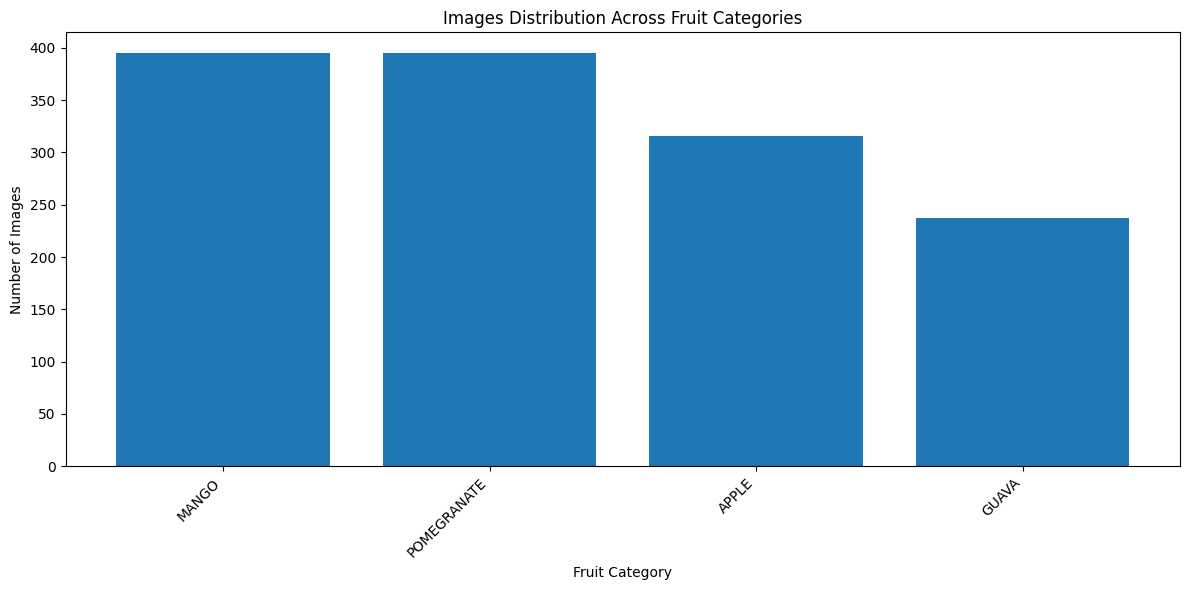

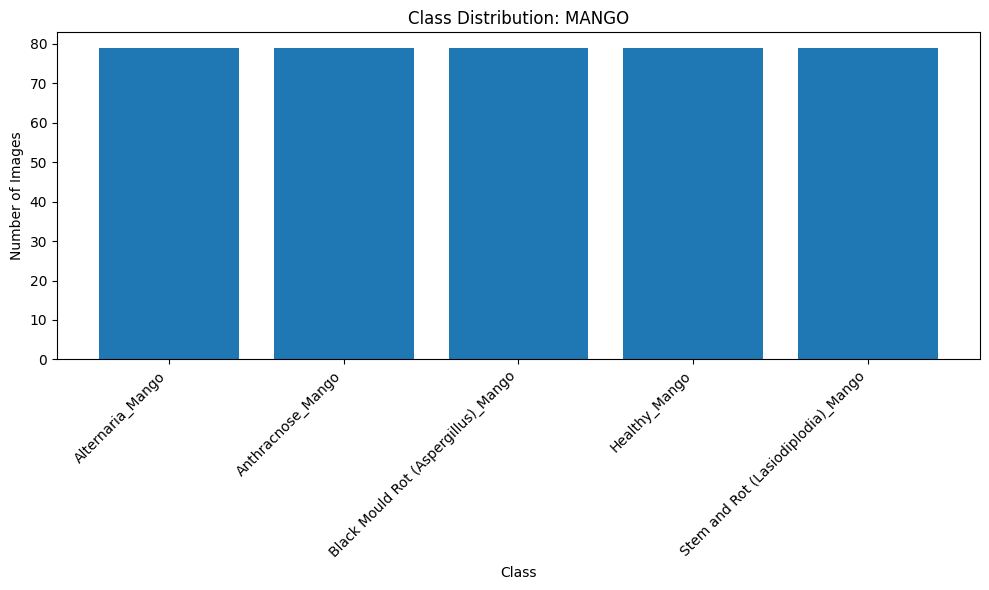

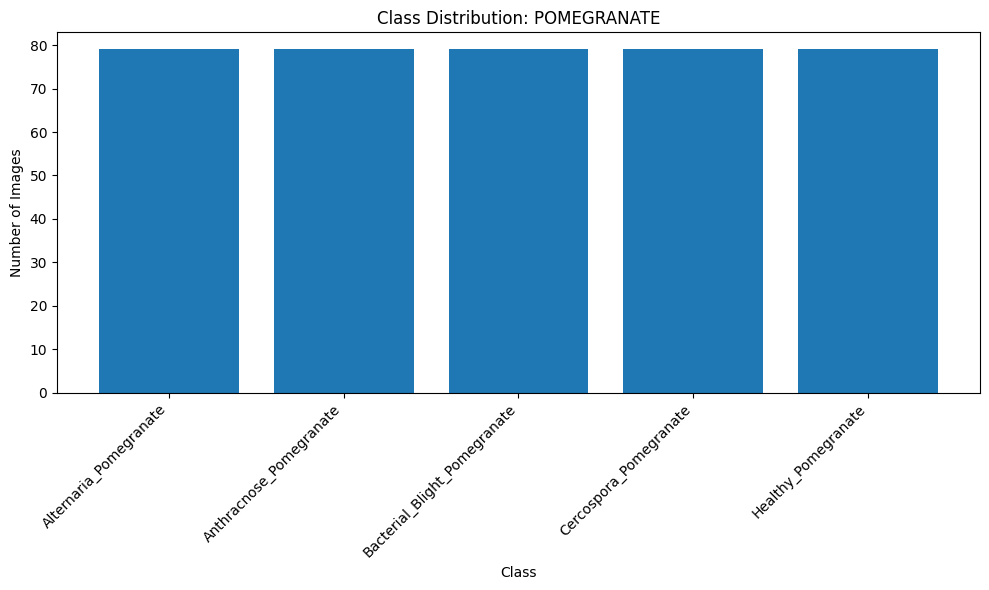

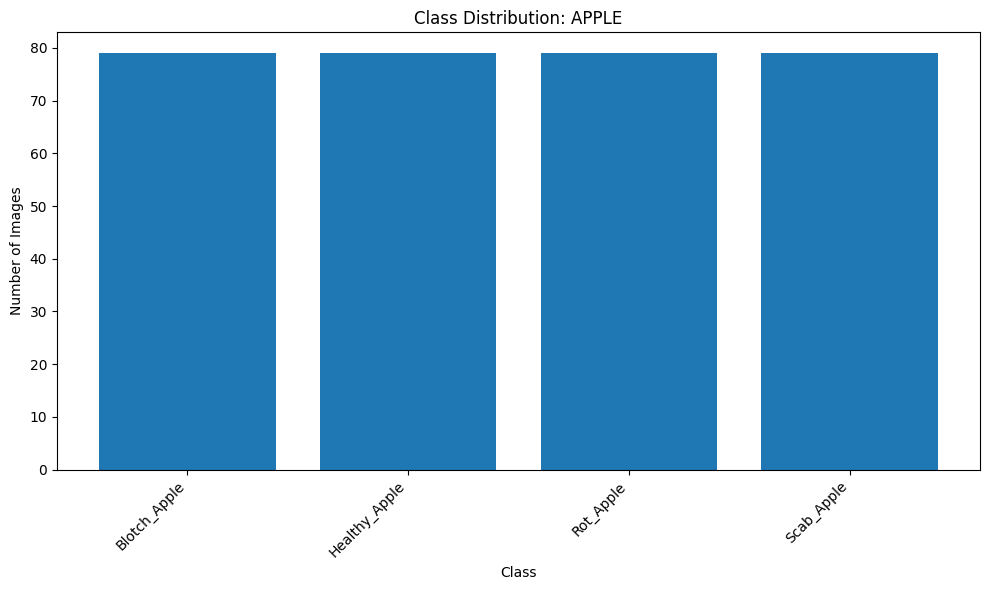


📊 Visualizations displayed and saved as PNG files


In [4]:
import os
import matplotlib.pyplot as plt
from collections import defaultdict
from tabulate import tabulate
import json


def get_image_files(directory):
    """Count valid image files in a directory."""
    image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
    return [f for f in os.listdir(directory) 
            if os.path.isfile(os.path.join(directory, f)) and 
            os.path.splitext(f.lower())[1] in image_extensions]


def summarize_dataset(dataset_path, visualize=False, export_format=None):
    """
    Analyze and summarize a hierarchical image dataset.
    
    Args:
        dataset_path: Path to the dataset directory
        visualize: Whether to generate visualization charts
        export_format: Format to export results ('json', 'csv', or None)
    """
    try:
        if not os.path.exists(dataset_path):
            raise FileNotFoundError(f"Dataset path not found: {dataset_path}")
            
        print(f"\n📊 Dataset Summary: {os.path.abspath(dataset_path)}\n")
        
        # Get fruit categories (top-level folders)
        fruits = [fruit for fruit in os.listdir(dataset_path) 
                 if os.path.isdir(os.path.join(dataset_path, fruit))]
        
        if not fruits:
            print("No categories found in the dataset directory.")
            return
            
        print(f"Found {len(fruits)} fruit categories\n")
        
        # Collect statistics
        dataset_stats = defaultdict(dict)
        total_images = 0
        fruit_counts = []
        
        # Prepare table data for console output
        table_data = []
        
        for fruit in sorted(fruits):
            fruit_path = os.path.join(dataset_path, fruit)
            fruit_total = 0
            classes = {}
            
            # Get class folders inside each fruit category
            class_folders = [cls for cls in os.listdir(fruit_path) 
                            if os.path.isdir(os.path.join(fruit_path, cls))]
            
            if not class_folders:
                print(f"Warning: No class folders found in {fruit}")
                continue
                
            class_rows = []
            
            for cls in sorted(class_folders):
                cls_path = os.path.join(fruit_path, cls)
                image_files = get_image_files(cls_path)
                image_count = len(image_files)
                
                # Store statistics
                classes[cls] = image_count
                fruit_total += image_count
                class_rows.append([f"  └─ {cls}", image_count])
            
            dataset_stats[fruit] = classes
            total_images += fruit_total
            fruit_counts.append((fruit, fruit_total))
            
            # Add to table data
            table_data.append([f"🍎 {fruit}", fruit_total, f"{len(classes)} classes"])
            table_data.extend(class_rows)
            table_data.append(["", "", ""])  # Empty row for spacing
        
        # Print summary table
        print(tabulate(table_data, headers=["Category/Class", "Images", "Details"], 
                      tablefmt="fancy_grid", numalign="right"))
        
        # Print overall statistics
        print(f"\n📈 Overall Statistics:")
        print(f"  Total categories: {len(fruits)}")
        print(f"  Total classes: {sum(len(dataset_stats[fruit]) for fruit in dataset_stats)}")
        print(f"  Total images: {total_images}")
        
        # Export data if requested
        if export_format:
            export_results(dataset_stats, export_format)
        
        # Visualize data if requested
        if visualize:
            create_visualizations(dataset_stats, fruit_counts)
            
        return dataset_stats
        
    except Exception as e:
        print(f"Error during dataset summarization: {str(e)}")
        return None


def export_results(stats, format_type):
    """Export dataset statistics to a file."""
    if format_type == 'json':
        with open('dataset_summary.json', 'w') as f:
            json.dump(stats, f, indent=2)
        print("\n✅ Summary exported to dataset_summary.json")
    elif format_type == 'csv':
        with open('dataset_summary.csv', 'w') as f:
            f.write("Category,Class,ImageCount\n")
            for category in stats:
                for cls, count in stats[category].items():
                    f.write(f"{category},{cls},{count}\n")
        print("\n✅ Summary exported to dataset_summary.csv")


def create_visualizations(stats, fruit_counts):
    """Create visualizations of the dataset statistics."""
    try:
        # Sort categories by image count for better visualization
        fruit_counts.sort(key=lambda x: x[1], reverse=True)
        
        # 1. Distribution of images across categories
        plt.figure(figsize=(12, 6))
        plt.bar([item[0] for item in fruit_counts], [item[1] for item in fruit_counts])
        plt.title('Images Distribution Across Fruit Categories')
        plt.xlabel('Fruit Category')
        plt.ylabel('Number of Images')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.savefig('category_distribution.png')
        plt.show()  # Added for notebook display
        
        # 2. Class distribution within top 3 fruits (if available)
        top_fruits = fruit_counts[:min(3, len(fruit_counts))]
        
        for fruit_name, _ in top_fruits:
            classes = stats[fruit_name]
            plt.figure(figsize=(10, 6))
            plt.bar(classes.keys(), classes.values())
            plt.title(f'Class Distribution: {fruit_name}')
            plt.xlabel('Class')
            plt.ylabel('Number of Images')
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.savefig(f'{fruit_name}_classes.png')
            plt.show()  # Added for notebook display
            
        print("\n📊 Visualizations displayed and saved as PNG files")
        
    except Exception as e:
        print(f"Error creating visualizations: {str(e)}")

stats = summarize_dataset(DATASET_PATH, visualize=True)

# Data Augmentation

In [5]:
# # %% AUGMENTATION CELL
# import tensorflow as tf
# from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
# import os
# import numpy as np
# from tqdm import tqdm
# import math
# from concurrent.futures import ThreadPoolExecutor
# import multiprocessing

# # Set TensorFlow to use GPU efficiently
# physical_devices = tf.config.list_physical_devices('GPU')
# if len(physical_devices) > 0:
#     for device in physical_devices:
#         tf.config.experimental.set_memory_growth(device, True)
#     print(f"Using {len(physical_devices)} GPU(s)")

# # --- Configuration ---
# AUGMENTED_DATASET_PATH = "Augmented_Dataset" # Directory to save augmented images
# TARGET_IMAGES_PER_CLASS = 100 # Target number of images per class *after* augmentation
# IMAGES_PER_CLASS_ORIGINAL = 79 # Must match the number used in the previous cell

# # --- Augmentation Parameters ---
# datagen = ImageDataGenerator(
#     rotation_range=40,          
#     width_shift_range=0.2,      
#     height_shift_range=0.2,     
#     shear_range=0.2,            
#     zoom_range=0.2,             
#     horizontal_flip=True,       
#     brightness_range=[0.8, 1.2], 
#     fill_mode='nearest'         
# )

# # --- Batch processing function ---
# def process_image_batch(batch_data):
#     """Process a batch of images for augmentation"""
#     class_target_path, img_paths, augmentations_per_image = batch_data
#     batch_generated = 0
    
#     for img_path in img_paths:
#         try:
#             img_name = os.path.basename(img_path)
#             img = load_img(img_path)
#             x = img_to_array(img)
#             x = x.reshape((1,) + x.shape)
            
#             img_save_prefix = os.path.splitext(img_name)[0]
            
#             # Generate augmentations in memory first
#             aug_images = []
#             for i, batch in enumerate(datagen.flow(x, batch_size=1)):
#                 aug_images.append((batch[0], f'{img_save_prefix}_aug_{i}.jpg'))
#                 if i >= augmentations_per_image - 1:
#                     break
            
#             # Now save them all at once
#             for img_array, filename in aug_images:
#                 save_path = os.path.join(class_target_path, filename)
#                 tf.keras.preprocessing.image.save_img(save_path, img_array)
#                 batch_generated += 1
                
#         except Exception as e:
#             print(f"\nError processing image {img_path}: {e}")
            
#     return batch_generated

# # --- Augmentation Function ---
# def augment_images(source_dir, target_dir, datagen, target_total_per_class, original_per_class):
#     """
#     Augments images from source_dir and saves them to target_dir.
#     """
#     if not os.path.exists(target_dir):
#         os.makedirs(target_dir)
#         print(f"Created augmented dataset directory: {target_dir}")
#     else:
#         print(f"Augmented dataset directory already exists: {target_dir}")

#     # Calculate augmentations needed per original image
#     if target_total_per_class <= original_per_class:
#          print(f"Warning: Target images ({target_total_per_class}) is not greater than original ({original_per_class}). No augmentation performed.")
#          return

#     augmentations_per_image = math.ceil(target_total_per_class / original_per_class)
#     print(f"Aiming for approximately {augmentations_per_image} augmented versions per original image to reach ~{target_total_per_class} total.")

#     total_generated = 0
#     processed_classes = 0

#     # Determine number of worker threads (typically 2-4x CPU cores for I/O bound tasks)
#     max_workers = min(multiprocessing.cpu_count() * 2, 16)  # Cap at 16 workers
#     print(f"Using {max_workers} worker threads for parallel processing")

#     # Iterate through fruit categories
#     fruits = [f for f in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, f))]
#     if not fruits:
#         fruits = [""]  # Use an empty string to process the top level directly

#     for fruit in tqdm(fruits, desc="Processing fruit categories"):
#         fruit_source_path = os.path.join(source_dir, fruit)
#         fruit_target_path = os.path.join(target_dir, fruit)

#         # Determine class directories
#         if fruit == "":
#              classes = [d for d in os.listdir(fruit_source_path) if os.path.isdir(os.path.join(fruit_source_path, d))]
#         else:
#              classes = [c for c in os.listdir(fruit_source_path) if os.path.isdir(os.path.join(fruit_source_path, c))]

#         for cls in tqdm(classes, desc=f"Processing classes in {fruit if fruit else 'root'}", leave=False):
#             processed_classes += 1
#             class_source_path = os.path.join(fruit_source_path, cls)
#             class_target_path = os.path.join(fruit_target_path, cls)

#             if not os.path.exists(class_target_path):
#                 os.makedirs(class_target_path)

#             image_files = [f for f in os.listdir(class_source_path) if os.path.isfile(os.path.join(class_source_path, f))]

#             if len(image_files) != original_per_class and fruit != "":
#                  print(f"  Warning: Class '{cls}' in '{fruit}' has {len(image_files)} images, expected {original_per_class}. Augmentation count might be inaccurate.")
#             elif len(image_files) == 0:
#                  print(f"  Warning: Class '{cls}' in '{fruit}' has 0 images. Skipping.")
#                  continue

#             # Prepare full paths for all images
#             img_paths = [os.path.join(class_source_path, img_name) for img_name in image_files]
            
#             # Split into batches for parallel processing
#             batch_size = max(1, len(img_paths) // max_workers)
#             batches = []
            
#             for i in range(0, len(img_paths), batch_size):
#                 batch_img_paths = img_paths[i:i+batch_size]
#                 batches.append((class_target_path, batch_img_paths, augmentations_per_image))
            
#             # Process batches in parallel
#             class_generated_count = 0
#             with ThreadPoolExecutor(max_workers=max_workers) as executor:
#                 results = list(executor.map(process_image_batch, batches))
#                 class_generated_count = sum(results)
                
#             total_generated += class_generated_count
#             print(f"  Generated {class_generated_count} images for class '{cls}'. Target was ~{target_total_per_class}.")

#     print(f"\n✅ Augmentation complete!")
#     print(f"   - Saved augmented images to: {target_dir}")
#     print(f"   - Total images generated: {total_generated}")
#     print(f"   - Number of classes processed: {processed_classes}")

# # --- Execute Augmentation ---
# augment_images(DATASET_PATH,
#                AUGMENTED_DATASET_PATH,
#                datagen,
#                TARGET_IMAGES_PER_CLASS,
#                IMAGES_PER_CLASS_ORIGINAL)

# print(f"Augmented dataset location: {AUGMENTED_DATASET_PATH}")
# print(f"Each class in {AUGMENTED_DATASET_PATH} should now have approximately {TARGET_IMAGES_PER_CLASS} images.")
# DATASET_PATH = AUGMENTED_DATASET_PATH

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import cv2
from pathlib import Path

In [7]:
# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# Training parameters
EPOCHS = 30
FINE_TUNE_EPOCHS = 30
TOTAL_EPOCHS = EPOCHS + FINE_TUNE_EPOCHS
LEARNING_RATE = 0.001
FINE_TUNE_LEARNING_RATE = LEARNING_RATE / 10
FINE_TUNE_AT_PERCENTAGE = 0.15

# Check GPU availability
print("GPU Available: ", tf.config.list_physical_devices('GPU'))

# Set random seed for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"\nTraining Plan:")
print(f" - Initial Epochs (Head Training): {EPOCHS} @ LR={LEARNING_RATE}")
print(f" - Fine-tuning Epochs: {FINE_TUNE_EPOCHS} @ LR={FINE_TUNE_LEARNING_RATE}")
print(f" - Total Epochs: {TOTAL_EPOCHS}")
print(f" - Fine-tuning unfreezes last ~{FINE_TUNE_AT_PERCENTAGE*100}% of base model layers.")

GPU Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Training Plan:
 - Initial Epochs (Head Training): 30 @ LR=0.001
 - Fine-tuning Epochs: 30 @ LR=0.0001
 - Total Epochs: 60
 - Fine-tuning unfreezes last ~15.0% of base model layers.


In [8]:
# Function to count files in subdirectories
# DATASET_PATH = AUGMENTED_DATASET_PATH
def count_files_in_dir(directory):
    count_dict = {}
    total_count = 0
    
    for fruit in os.listdir(directory):
        fruit_path = os.path.join(directory, fruit)
        if os.path.isdir(fruit_path):
            count_dict[fruit] = {}
            fruit_total = 0
            
            for disease in os.listdir(fruit_path):
                disease_path = os.path.join(fruit_path, disease)
                if os.path.isdir(disease_path):
                    file_count = len([f for f in os.listdir(disease_path) if os.path.isfile(os.path.join(disease_path, f))])
                    count_dict[fruit][disease] = file_count
                    fruit_total += file_count
            
            count_dict[fruit]['total'] = fruit_total
            total_count += fruit_total
    
    count_dict['grand_total'] = total_count
    return count_dict

# Count files and display dataset structure
file_counts = count_files_in_dir(DATASET_PATH)
print("Dataset Structure:")
for fruit, diseases in file_counts.items():
    if fruit != 'grand_total':
        print(f"\n{fruit}:")
        for disease, count in diseases.items():
            if disease != 'total':
                print(f"  - {disease}: {count} images")
        print(f"  Total {fruit} images: {diseases['total']}")

print(f"\nTotal images in dataset: {file_counts['grand_total']}")

# Create a list of all classes
all_classes = []
for fruit in os.listdir(DATASET_PATH):
    fruit_path = os.path.join(DATASET_PATH, fruit)
    if os.path.isdir(fruit_path):
        for disease in os.listdir(fruit_path):
            all_classes.append(f"{fruit}_{disease}")

print(f"\nTotal number of classes: {len(all_classes)}")
print("Classes:", all_classes)

Dataset Structure:

APPLE:
  - Rot_Apple: 79 images
  - Healthy_Apple: 79 images
  - Blotch_Apple: 79 images
  - Scab_Apple: 79 images
  Total APPLE images: 316

POMEGRANATE:
  - Alternaria_Pomegranate: 79 images
  - Healthy_Pomegranate: 79 images
  - Anthracnose_Pomegranate: 79 images
  - Bacterial_Blight_Pomegranate: 79 images
  - Cercospora_Pomegranate: 79 images
  Total POMEGRANATE images: 395

MANGO:
  - Healthy_Mango: 79 images
  - Alternaria_Mango: 79 images
  - Black Mould Rot (Aspergillus)_Mango: 79 images
  - Anthracnose_Mango: 79 images
  - Stem and Rot (Lasiodiplodia)_Mango: 79 images
  Total MANGO images: 395

GUAVA:
  - Healthy_Guava: 79 images
  - Fruitfly_Guava: 79 images
  - Anthracnose_Guava: 79 images
  Total GUAVA images: 237

Total images in dataset: 1343

Total number of classes: 17
Classes: ['APPLE_Rot_Apple', 'APPLE_Healthy_Apple', 'APPLE_Blotch_Apple', 'APPLE_Scab_Apple', 'POMEGRANATE_Alternaria_Pomegranate', 'POMEGRANATE_Healthy_Pomegranate', 'POMEGRANATE_Anth

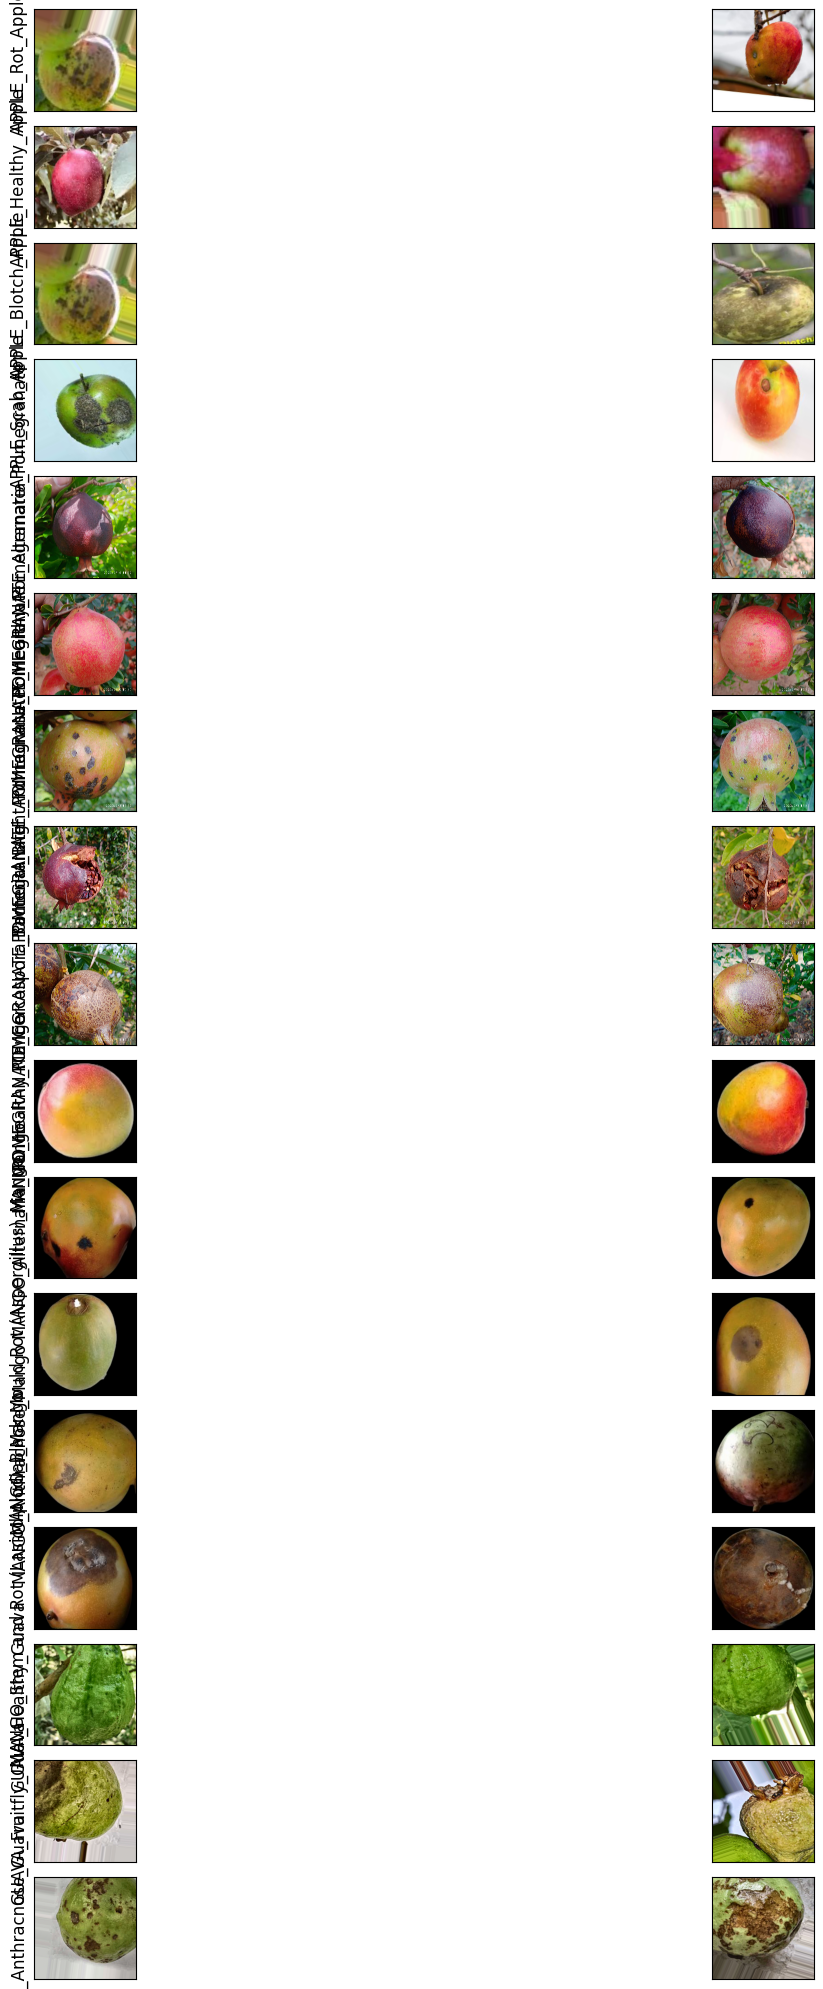

In [9]:
def plot_sample_images(dataset_path, num_samples=3):
    """Plot sample images from each class"""
    fig = plt.figure(figsize=(20, 20))
    
    class_index = 0
    for fruit in os.listdir(dataset_path):
        fruit_path = os.path.join(dataset_path, fruit)
        if os.path.isdir(fruit_path):
            for disease in os.listdir(fruit_path):
                disease_path = os.path.join(fruit_path, disease)
                if os.path.isdir(disease_path):
                    image_files = [f for f in os.listdir(disease_path) 
                                  if os.path.isfile(os.path.join(disease_path, f)) and 
                                  f.lower().endswith(('png', 'jpg', 'jpeg'))]
                    
                    if image_files:
                        for i in range(min(num_samples, len(image_files))):
                            sample_img_path = os.path.join(disease_path, image_files[i])
                            img = cv2.imread(sample_img_path)
                            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                            
                            ax = fig.add_subplot(len(all_classes), num_samples, class_index * num_samples + i + 1)
                            ax.imshow(img)
                            if i == 0:
                                ax.set_ylabel(f"{fruit}_{disease}", fontsize=12)
                            ax.set_xticks([])
                            ax.set_yticks([])
                    
                    class_index += 1
    
    plt.tight_layout()
    plt.show()

# Plot sample images from each class
plot_sample_images(DATASET_PATH, num_samples=2)

In [10]:
# Modified Cell (Originally defining prepare_data_generators)
# Place this cell BEFORE you define or create the models.

import os
import shutil
import numpy as np
import math
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split # For more robust splitting (alternative)
# Import the preprocessing function you want to use (e.g., for EfficientNet)
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess_input
# from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess_input
# from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess_input

# Choose ONE preprocessing function if applying universally to transfer models
# Set to None if you want to only use rescale=1./255
PREPROCESS_FUNC = efficientnet_preprocess_input
# PREPROCESS_FUNC = None # Use this if you only want rescale=1./255 for all models

def prepare_data_generators(dataset_path, img_height, img_width, batch_size,
                            validation_split_ratio=0.2, test_split_ratio=0.1,
                            min_images_per_class_final=5, seed=42,
                            use_specific_preprocessing=True): # Added flag
    """
    Prepares data generators for training, validation, and testing with improved splitting, logging,
    and option for model-specific preprocessing.

    Args:
        dataset_path: Path to the main dataset directory (e.g., Augmented_Dataset).
        img_height, img_width: Target image dimensions.
        batch_size: Batch size for generators.
        validation_split_ratio: Proportion of data for validation (e.g., 0.2 for 20%).
        test_split_ratio: Proportion of data for testing (e.g., 0.1 for 10%).
        min_images_per_class_final: Minimum images required per class in train, val, AND test sets.
        seed: Random seed for reproducibility.
        use_specific_preprocessing: If True and PREPROCESS_FUNC is set, uses it. Otherwise uses rescale=1./255.
    """
    print(f"\n--- Preparing Data Generators ---")
    print(f"Source Dataset: {dataset_path}")
    print(f"Validation Split: {validation_split_ratio * 100}%, Test Split: {test_split_ratio * 100}%")
    print(f"Minimum images per class required (Train/Val/Test): {min_images_per_class_final}")

    flattened_dir = 'flattened_dataset_split'
    train_dir = os.path.join(flattened_dir, 'train')
    val_dir = os.path.join(flattened_dir, 'validation')
    test_dir = os.path.join(flattened_dir, 'test')

    # Clean up existing split directories if they exist
    if os.path.exists(flattened_dir):
        print(f"Removing existing split directory: {flattened_dir}")
        shutil.rmtree(flattened_dir)

    os.makedirs(train_dir)
    os.makedirs(val_dir)
    os.makedirs(test_dir)
    print(f"Created new split directories: {train_dir}, {val_dir}, {test_dir}")

    all_classes = []
    all_filepaths = []
    class_counts_initial = {}

    print("\nScanning original dataset structure...")
    # Iterate through fruit categories first
    for fruit_type in sorted(os.listdir(dataset_path)):
        fruit_dir = os.path.join(dataset_path, fruit_type)
        if not os.path.isdir(fruit_dir):
            continue

        print(f"  Processing Fruit: {fruit_type}")
        # Iterate through conditions (diseases/healthy)
        for condition in sorted(os.listdir(fruit_dir)):
            condition_dir = os.path.join(fruit_dir, condition)
            if not os.path.isdir(condition_dir):
                continue

            class_name = f"{fruit_type}_{condition}"
            all_classes.append(class_name)
            class_counts_initial[class_name] = 0

            image_files = [f for f in os.listdir(condition_dir)
                           if os.path.isfile(os.path.join(condition_dir, f)) and
                           f.lower().endswith(('.png', '.jpg', '.jpeg'))]

            print(f"    - Class: {class_name}, Found images: {len(image_files)}")
            class_counts_initial[class_name] = len(image_files)

            # Collect full paths and class names
            for img_file in image_files:
                all_filepaths.append((os.path.join(condition_dir, img_file), class_name))

            # Create corresponding class directories in train/val/test
            os.makedirs(os.path.join(train_dir, class_name), exist_ok=True)
            os.makedirs(os.path.join(val_dir, class_name), exist_ok=True)
            os.makedirs(os.path.join(test_dir, class_name), exist_ok=True)

            # Specific check (example)
            # if 'GUAVA' in fruit_type.upper() and len(image_files) == 0:
            #      print(f"      WARNING: GUAVA class '{class_name}' has 0 images initially!")


    print(f"\nTotal classes found initially: {len(all_classes)}")
    if not all_classes:
        raise ValueError("No classes found in the dataset path!")

    # --- Splitting Data ---
    print("\nSplitting data into Train, Validation, Test sets...")
    random_state = np.random.RandomState(seed)
    random_state.shuffle(all_filepaths) # Shuffle before splitting

    train_files, val_test_files = train_test_split(
        all_filepaths,
        test_size=(validation_split_ratio + test_split_ratio),
        random_state=seed,
        stratify=[label for _, label in all_filepaths] # Stratify to keep class proportions
    )

    # Adjust test split ratio relative to the val_test subset
    relative_test_split = test_split_ratio / (validation_split_ratio + test_split_ratio)

    val_files, test_files = train_test_split(
        val_test_files,
        test_size=relative_test_split,
        random_state=seed,
        stratify=[label for _, label in val_test_files] # Stratify again
    )

    print(f"Total files: {len(all_filepaths)}")
    print(f"Train files: {len(train_files)}")
    print(f"Validation files: {len(val_files)}")
    print(f"Test files: {len(test_files)}")


    # --- Populate Directories & Filter Classes ---
    print("\nPopulating split directories and checking class counts...")
    final_class_counts = {'train': {}, 'validation': {}, 'test': {}}
    valid_classes = set(all_classes)

    for split_name, split_files, target_base_dir in [('train', train_files, train_dir),
                                                    ('validation', val_files, val_dir),
                                                    ('test', test_files, test_dir)]:
        print(f"  Populating {split_name} set...")
        split_class_counts = {cls: 0 for cls in all_classes}
        for src_path, class_name in split_files:
            # Ensure class directory exists before creating link/copy
            os.makedirs(os.path.join(target_base_dir, class_name), exist_ok=True)
            dst_path = os.path.join(target_base_dir, class_name, os.path.basename(src_path))
            try:
                 # Use symlink if possible (faster, less space) - needs absolute source path
                 os.symlink(os.path.abspath(src_path), dst_path)
            except OSError:
                 # Fallback to copy if symlink fails (e.g., different filesystems, Windows permissions)
                 # print(f"    Symlink failed for {src_path}, copying instead.") # Optional debug print
                 shutil.copy2(src_path, dst_path)
            except Exception as e:
                print(f"ERROR copying/linking {src_path} to {dst_path}: {e}")
                continue # Skip counting if file fails to link/copy

            split_class_counts[class_name] += 1
        final_class_counts[split_name] = split_class_counts

        # Check for minimum images in this split
        for class_name in list(all_classes): # Iterate over a copy
             if split_class_counts.get(class_name, 0) < min_images_per_class_final:
                 print(f"    WARNING: Class '{class_name}' has only {split_class_counts.get(class_name, 0)} images in {split_name} set (minimum is {min_images_per_class_final}). This class will be removed.")
                 valid_classes.discard(class_name)


    print(f"\nInitial classes: {len(all_classes)}. Valid classes after minimum count check: {len(valid_classes)}")
    # Example check:
    # if 'GUAVA_Healthy' not in valid_classes and 'GUAVA_Healthy' in all_classes:
    #      print("  NOTE: 'GUAVA_Healthy' (or other GUAVA class) was removed due to insufficient images in one of the splits.")


    # --- Remove invalid class directories ---
    print("\nRemoving directories for classes failing minimum count requirement...")
    removed_count = 0
    for split_dir in [train_dir, val_dir, test_dir]:
        for class_name in os.listdir(split_dir):
            class_dir_path = os.path.join(split_dir, class_name)
            if class_name not in valid_classes and os.path.isdir(class_dir_path):
                 print(f"  Removing: {class_dir_path}")
                 shutil.rmtree(class_dir_path)
                 removed_count +=1
    if removed_count == 0:
         print("  No class directories needed removal.")

    final_class_names = sorted(list(valid_classes))
    num_final_classes = len(final_class_names)
    if num_final_classes == 0:
        raise ValueError("No classes remaining after filtering! Check dataset and min_images_per_class_final.")
    print(f"\nFinal number of classes for training: {num_final_classes}")
    #print("Final Classes:", final_class_names) # Uncomment if needed, can be long

    # --- Create Generators ---
    print("\nCreating ImageDataGenerators...")

    # Determine if using specific preprocessing or just rescale
    if use_specific_preprocessing and PREPROCESS_FUNC:
        print(f"Using specific preprocessing function: {PREPROCESS_FUNC.__name__}")
        # Training generator with augmentation AND specific preprocessing
        train_datagen = ImageDataGenerator(
            preprocessing_function=PREPROCESS_FUNC, # Use the specific function
            rotation_range=30,
            width_shift_range=0.2,
            height_shift_range=0.2,
            shear_range=0.2,
            zoom_range=0.2,
            horizontal_flip=True,
            brightness_range=[0.8, 1.2],
            fill_mode='nearest'
        )
        # Validation and Test generators use ONLY the specific preprocessing
        val_test_datagen = ImageDataGenerator(preprocessing_function=PREPROCESS_FUNC)
    else:
        print("Using rescale=1./255 for normalization.")
        # Training generator with augmentation and rescale
        train_datagen = ImageDataGenerator(
            rescale=1./255, # Use rescale
            rotation_range=30,
            width_shift_range=0.2,
            height_shift_range=0.2,
            shear_range=0.2,
            zoom_range=0.2,
            horizontal_flip=True,
            brightness_range=[0.8, 1.2],
            fill_mode='nearest'
        )
        # Validation and Test generators just rescale
        val_test_datagen = ImageDataGenerator(rescale=1./255)


    train_generator = train_datagen.flow_from_directory(
        train_dir,
        target_size=(img_height, img_width),
        batch_size=batch_size,
        class_mode='categorical',
        classes=final_class_names, # Ensure consistent class order
        shuffle=True,
        seed=seed
    )

    validation_generator = val_test_datagen.flow_from_directory(
        val_dir,
        target_size=(img_height, img_width),
        batch_size=batch_size,
        class_mode='categorical',
        classes=final_class_names, # Ensure consistent class order
        shuffle=False # No need to shuffle validation
    )

    test_generator = val_test_datagen.flow_from_directory(
        test_dir,
        target_size=(img_height, img_width),
        batch_size=batch_size,
        class_mode='categorical',
        classes=final_class_names, # Ensure consistent class order
        shuffle=False # No need to shuffle test
    )

    # Final check on generator class consistency
    if not (train_generator.num_classes == validation_generator.num_classes == test_generator.num_classes == num_final_classes):
        print("\n!!! WARNING: Mismatch in number of classes between generators !!!")
        print(f"  Train: {train_generator.num_classes}, Val: {validation_generator.num_classes}, Test: {test_generator.num_classes}, Expected: {num_final_classes}")
        print(f"  Train Classes: {train_generator.classes}") # Debug: show actual classes found by generator
        print(f"  Val Classes: {validation_generator.classes}")
        print(f"  Test Classes: {test_generator.classes}")
        print(f"  Expected Final Classes: {final_class_names}")
        # print(f"  Train Indices: {train_generator.class_indices}") # Already printed later
        # print(f"  Val Indices: {validation_generator.class_indices}")
        # print(f"  Test Indices: {test_generator.class_indices}")
        raise ValueError("Class mismatch detected between expected list and generators. Check filtering logic or directory structure.")


    print("\n--- Data Generators Prepared Successfully ---")
    return train_generator, validation_generator, test_generator, final_class_names


# How to call it (place this cell where you previously called prepare_data_generators):
# Call the revised function, deciding whether to use specific preprocessing
# If you mainly use EfficientNetB0, set use_specific_preprocessing=True
# If you want to test CustomCNN first, set it to False

# IMAGE PARAMETERS (Assuming these are defined earlier)
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
SEED = 42
DATASET_PATH = "Dev_Dataset" # Or your final augmented dataset path

train_generator, validation_generator, test_generator, class_names = prepare_data_generators(
    dataset_path=DATASET_PATH, # Should be Augmented_Dataset path
    img_height=IMG_HEIGHT,
    img_width=IMG_WIDTH,
    batch_size=BATCH_SIZE,
    validation_split_ratio=0.15, # e.g., 15% validation
    test_split_ratio=0.15,       # e.g., 15% test -> 70% train
    min_images_per_class_final=10, # Increase minimum required images slightly
    seed=SEED,
    use_specific_preprocessing=True # SET TO True TO USE PREPROCESS_FUNC (e.g., EfficientNetB0's)
                                    # SET TO False TO USE ONLY rescale=1./255
)

# Display class indices and sample counts
print("\nClass indices:", train_generator.class_indices)
print(f"Training samples: {train_generator.samples} (Batches: {len(train_generator)})")
print(f"Validation samples: {validation_generator.samples} (Batches: {len(validation_generator)})")
print(f"Test samples: {test_generator.samples} (Batches: {len(test_generator)})")
if train_generator.num_classes > 0:
     num_classes = train_generator.num_classes # Update num_classes based on final valid classes
     print(f"Number of classes after filtering: {num_classes}")
else:
     raise ValueError("Train generator reported 0 classes!")


--- Preparing Data Generators ---
Source Dataset: Dev_Dataset
Validation Split: 15.0%, Test Split: 15.0%
Minimum images per class required (Train/Val/Test): 10
Created new split directories: flattened_dataset_split/train, flattened_dataset_split/validation, flattened_dataset_split/test

Scanning original dataset structure...
  Processing Fruit: APPLE
    - Class: APPLE_Blotch_Apple, Found images: 79
    - Class: APPLE_Healthy_Apple, Found images: 79
    - Class: APPLE_Rot_Apple, Found images: 79
    - Class: APPLE_Scab_Apple, Found images: 79
  Processing Fruit: GUAVA
    - Class: GUAVA_Anthracnose_Guava, Found images: 79
    - Class: GUAVA_Fruitfly_Guava, Found images: 79
    - Class: GUAVA_Healthy_Guava, Found images: 79
  Processing Fruit: MANGO
    - Class: MANGO_Alternaria_Mango, Found images: 79
    - Class: MANGO_Anthracnose_Mango, Found images: 79
    - Class: MANGO_Black Mould Rot (Aspergillus)_Mango, Found images: 79
    - Class: MANGO_Healthy_Mango, Found images: 79
    - C

In [11]:
def create_custom_cnn_model(input_shape, num_classes):
    """Create a custom CNN model"""
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    return model


def create_mobilenetv2_model(input_shape, num_classes):
    """Create a MobileNetV2 model with transfer learning"""
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    
    # Freeze the base model
    base_model.trainable = False
    
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    return model

def create_efficientnet_model(input_shape, num_classes):
    """Create an EfficientNetB0 model with transfer learning"""
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=input_shape)
    
    # Freeze the base model
    base_model.trainable = False
    
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    return model

def create_resnet50_model(input_shape, num_classes):
    """Create a ResNet50 model with transfer learning"""
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    
    # Freeze the base model
    base_model.trainable = False
    
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    return model

# Get number of classes from data generator
num_classes = train_generator.num_classes # Use the actual number from the final generator
if num_classes == 0:
     raise ValueError("No classes found by the data generator. Check dataset path and filtering.")
print(f"Number of classes determined by generator: {num_classes}")
input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)

def create_transfer_learning_model(base_model_func, input_shape, num_classes, freeze_base=True):
    """Creates a model using a pre-trained base with a new classifier head."""
    # Create the base model
    base_model = base_model_func(weights='imagenet', include_top=False, input_shape=input_shape)

    # Freeze the base model initially
    base_model.trainable = not freeze_base

    # Add the classifier head
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(1024, activation='relu'), # Slightly larger Dense layer
        layers.Dropout(0.5),                 # Strong dropout
        layers.Dense(512, activation='relu'),
        # layers.Dropout(0.3), # Removed second dropout for simplicity, can add back if needed
        layers.Dense(num_classes, activation='softmax')
    ])
    return model, base_model # Return base_model for fine-tuning access

# Create models
models_to_train = {
    'Custom_CNN': create_custom_cnn_model(input_shape, num_classes),
    'MobileNetV2': create_mobilenetv2_model(input_shape, num_classes),
    'EfficientNetB0': create_efficientnet_model(input_shape, num_classes),
    'ResNet50': create_resnet50_model(input_shape, num_classes)
}

base_models = {} 

# Transfer learning models
transfer_model_configs = {
    'MobileNetV2': MobileNetV2,
    'EfficientNetB0': EfficientNetB0,
    'ResNet50': ResNet50
}

for name, model_func in transfer_model_configs.items():
     print(f"Creating {name}...")
     models_to_train[name], base_models[name] = create_transfer_learning_model(
         model_func, input_shape, num_classes, freeze_base=True # Start frozen
     )

# # Print model summaries
# for model_name, model in models_to_train.items():
#     print(f"\n{model_name} Model Summary:")
#     model.summary()

for model_name, model in models_to_train.items():
    print(f"\n--- {model_name} Model Summary (Initial State) ---")
    model.summary()
    if model_name in base_models:
         print(f"Base model ({model_name}) initially frozen: {not base_models[model_name].trainable}")    

Number of classes determined by generator: 17


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Creating MobileNetV2...
Creating EfficientNetB0...
Creating ResNet50...

--- Custom_CNN Model Summary (Initial State) ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 24, 24, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36864)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 36864)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │      18,874,880 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 17)                  │           8,721 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_5           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 17)                  │           8,721 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,219,409 (100.02 MB)

 Trainable params: 2,631,697 (10.04 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Base model (ResNet50) initially frozen: True


In [12]:
def train_model(model, model_name, train_gen, val_gen, epochs=EPOCHS, learning_rate=LEARNING_RATE):
    """Train the model and return history and trained model"""
    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # Callbacks
    checkpoint_path = f"models/{model_name}_best.keras"
    os.makedirs('models', exist_ok=True)
    
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ModelCheckpoint(filepath=checkpoint_path, monitor='val_accuracy', save_best_only=True, mode='max'),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6)
    ]
    
    # Train model
    history = model.fit(
        train_gen,
        epochs=epochs,
        validation_data=val_gen,
        callbacks=callbacks
    )
    
    return model, history

def evaluate_model(model, test_gen):
    """Evaluate model on test data"""
    # Evaluate the model
    test_loss, test_acc = model.evaluate(test_gen)
    print(f"Test accuracy: {test_acc:.4f}")
    print(f"Test loss: {test_loss:.4f}")
    
    # Get predictions
    test_gen.reset()
    y_pred = []
    y_true = []
    
    batch_index = 0
    max_batches = test_gen.samples // test_gen.batch_size + 1
    
    for x, y in test_gen:
        batch_index += 1
        if batch_index > max_batches:
            break
        
        y_pred.extend(np.argmax(model.predict(x), axis=1))
        y_true.extend(np.argmax(y, axis=1))
    
    # Create classification report
    class_names = list(test_gen.class_indices.keys())
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    return test_acc, report, cm

def plot_training_history(history, model_name):
    """Plot training and validation accuracy/loss curves"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
    
    # Accuracy plot
    ax1.plot(history.history['accuracy'], label='Training Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title(f'{model_name} - Accuracy')
    ax1.set_ylabel('Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.legend()
    
    # Loss plot
    ax2.plot(history.history['loss'], label='Training Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title(f'{model_name} - Loss')
    ax2.set_ylabel('Loss')
    ax2.set_xlabel('Epoch')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(cm, class_names, model_name):
    """Plot confusion matrix"""
    plt.figure(figsize=(15, 12))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


==== Training Custom_CNN ====
Epoch 1/30


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.0667 - loss: 65.1629 - val_accuracy: 0.0945 - val_loss: 2.5577 - learning_rate: 0.0010
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 823ms/step - accuracy: 0.1190 - loss: 2.6077 - val_accuracy: 0.1343 - val_loss: 2.5165 - learning_rate: 0.0010
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 801ms/step - accuracy: 0.1378 - loss: 2.5559 - val_accuracy: 0.1393 - val_loss: 2.4946 - learning_rate: 0.0010
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 770ms/step - accuracy: 0.1207 - loss: 2.4956 - val_accuracy: 0.1343 - val_loss: 2.4454 - learning_rate: 0.0010
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 795ms/step - accuracy: 0.1586 - loss: 2.4459 - val_accuracy: 0.1542 - val_loss: 2.3571 - learning_rate: 0.0010
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 803ms/step - accuracy: 0.1322 - loss: 2.4335 - val_accuracy: 0.1791 - val_loss: 2.3599 - learning_rate: 0.0010
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 779ms/step - accuracy: 0.1823 - loss: 2.3578 - val_ac

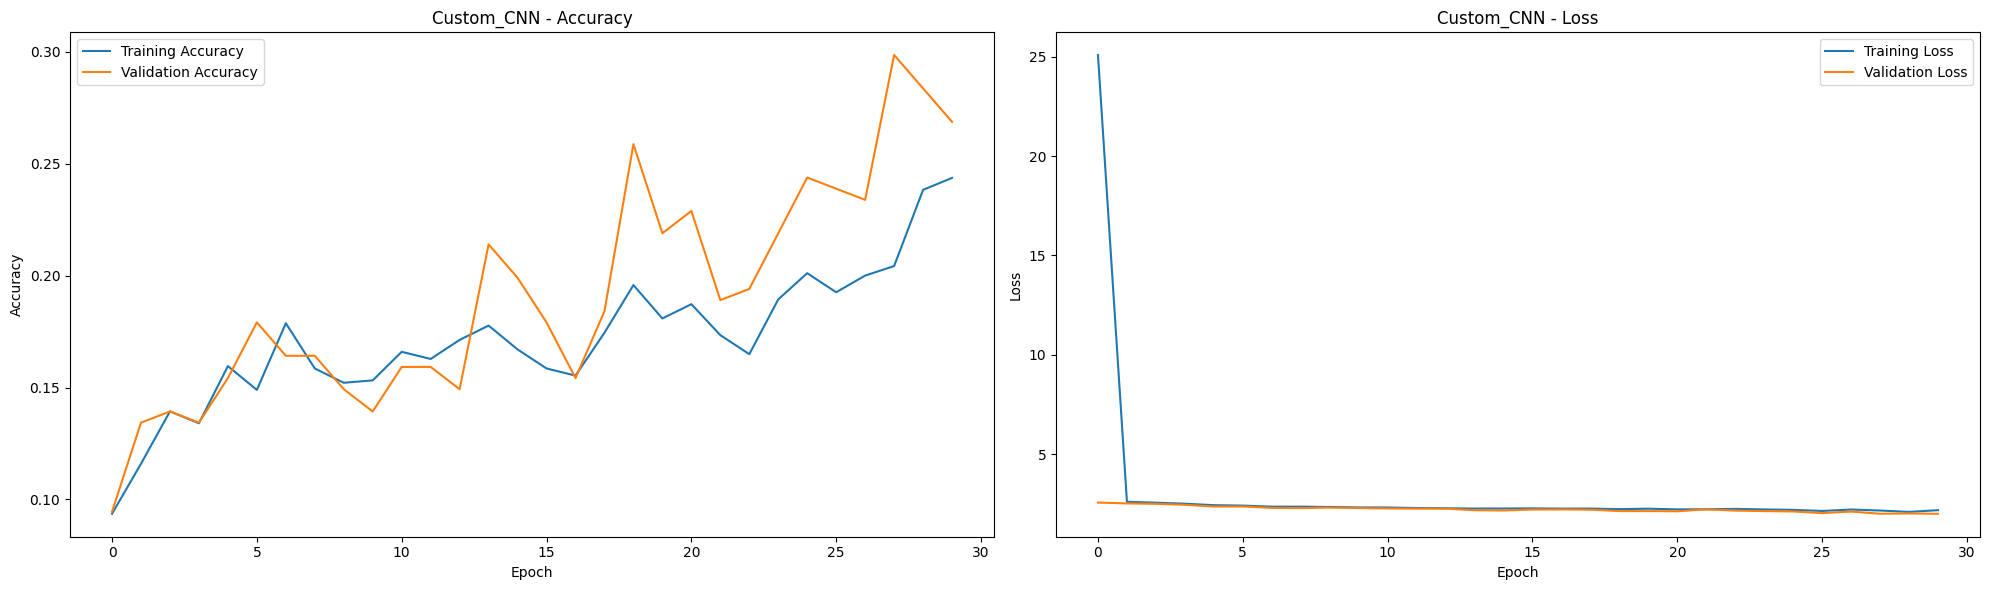


==== Evaluating Custom_CNN ====
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 709ms/step - accuracy: 0.2305 - loss: 2.1197
Test accuracy: 0.2723
Test loss: 1.9993
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


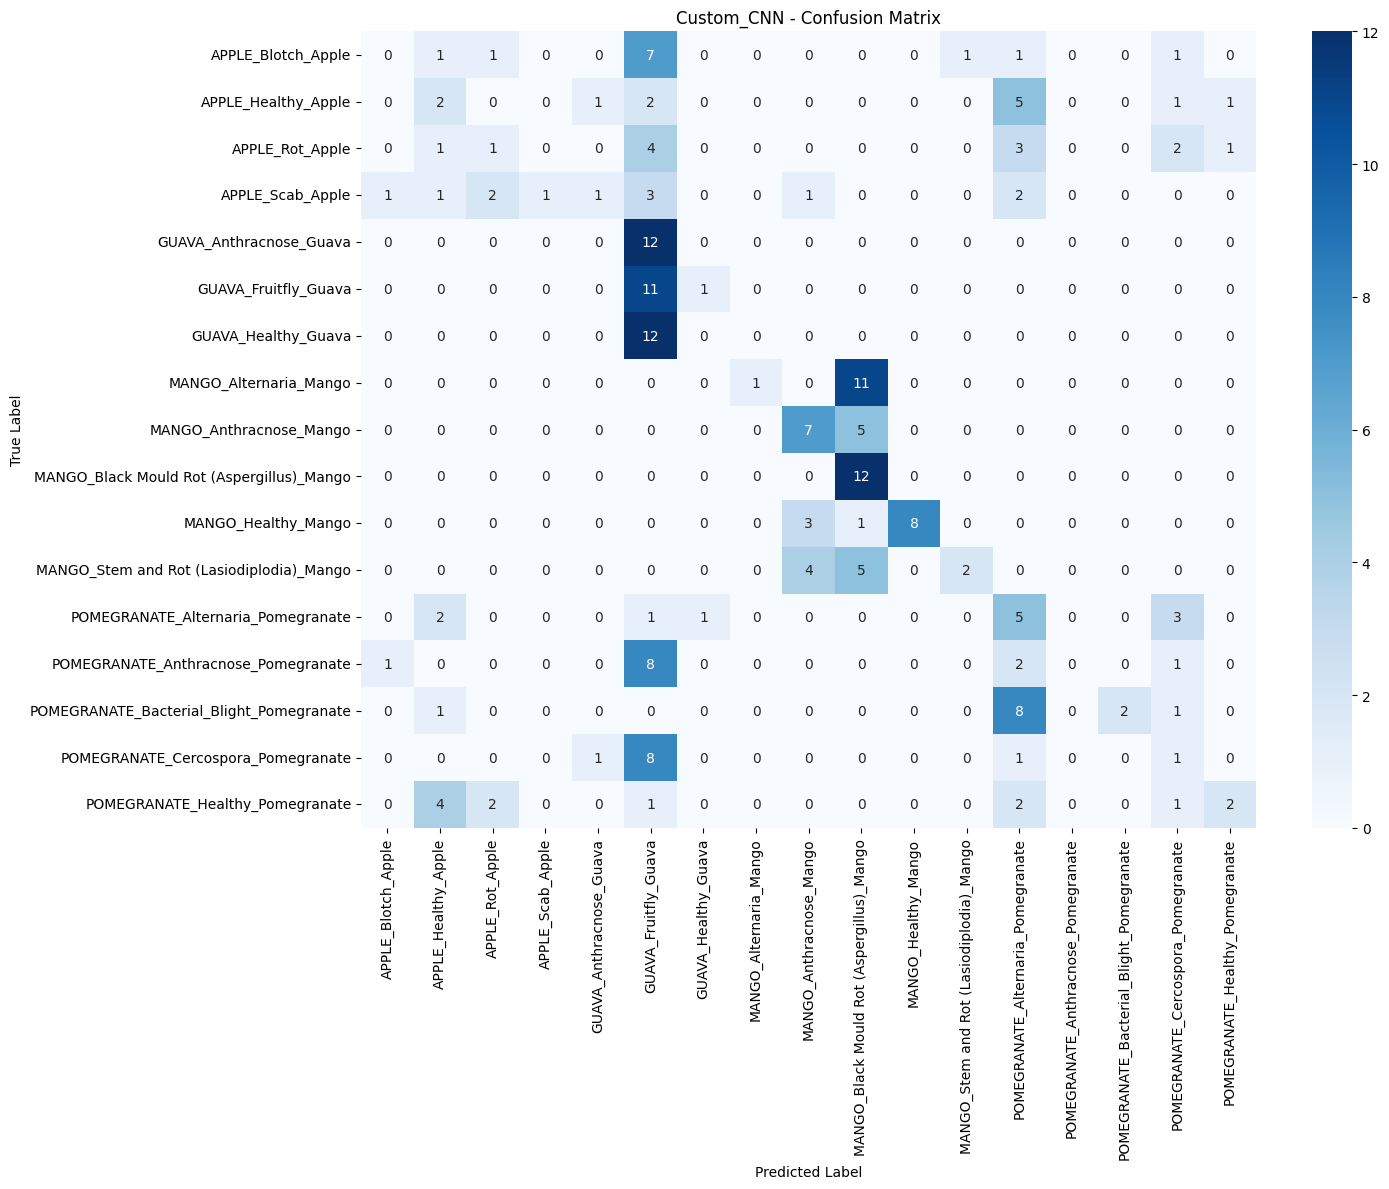

Model saved as models/Custom_CNN_final.keras
Results updated and saved to results/model_results.pkl

==== Training MobileNetV2 ====
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.1573 - loss: 2.7142 - val_accuracy: 0.3582 - val_loss: 1.6331 - learning_rate: 0.0010
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 771ms/step - accuracy: 0.3302 - loss: 1.8064 - val_accuracy: 0.3781 - val_loss: 1.5826 - learning_rate: 0.0010
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 771ms/step - accuracy: 0.3779 - loss: 1.6922 - val_accuracy: 0.4378 - val_loss: 1.4370 - learning_rate: 0.0010
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 755ms/step - accuracy: 0.4500 - loss: 1.4479 - val_accuracy: 0.5025 - val_loss: 1.2712 - learning_rate: 0.0010
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 755ms/step - accuracy: 0.4887 - loss: 1.3363 - val_accuracy: 0.5522 - val_loss: 1.2097 - learning_rate: 0.0010
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 773ms/step - accuracy: 0.4968 - loss: 1.3398 - val_accuracy: 0.5

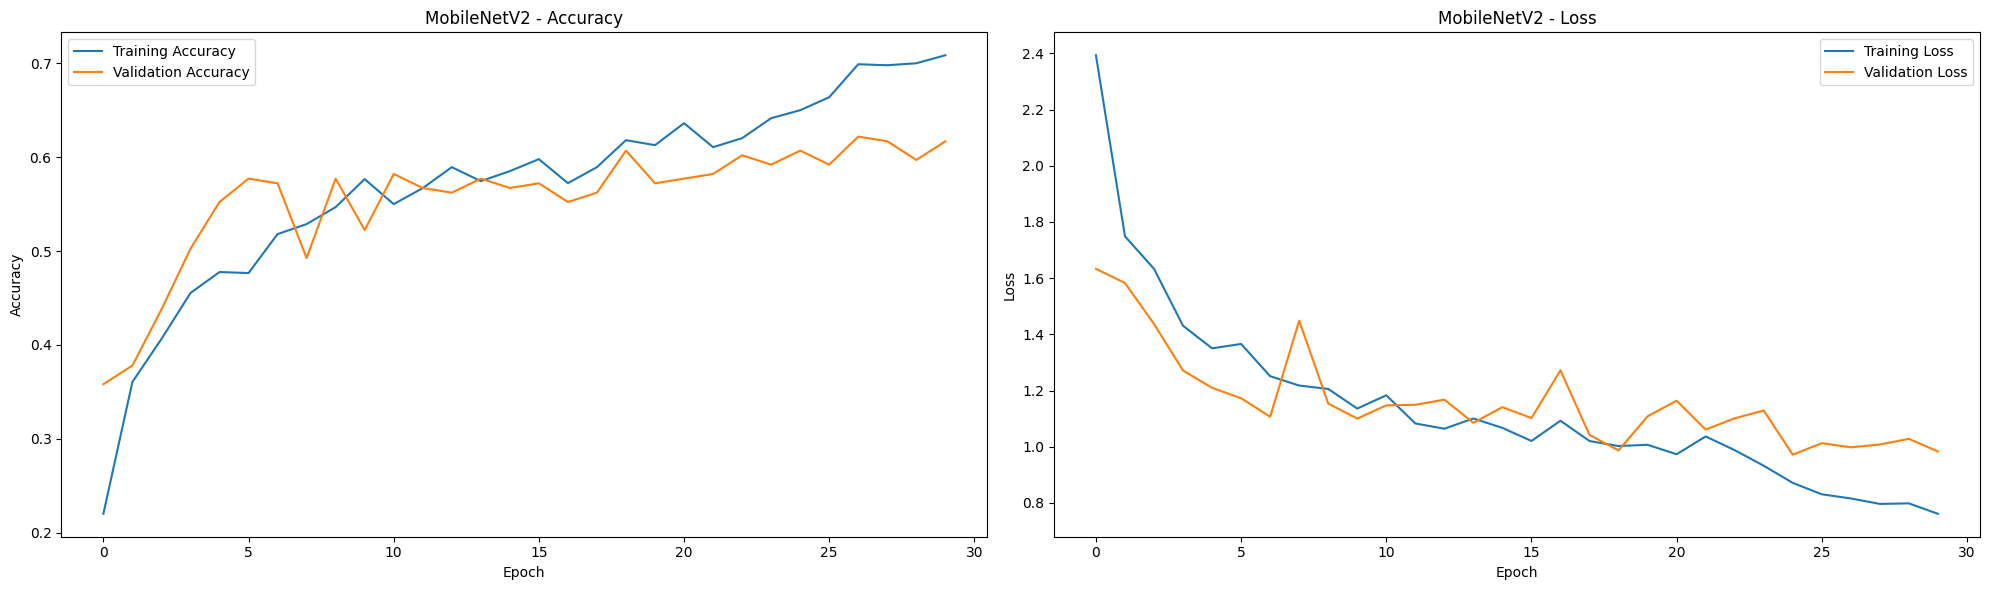


==== Evaluating MobileNetV2 ====
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 994ms/step - accuracy: 0.5835 - loss: 1.0163
Test accuracy: 0.6139
Test loss: 0.9280
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


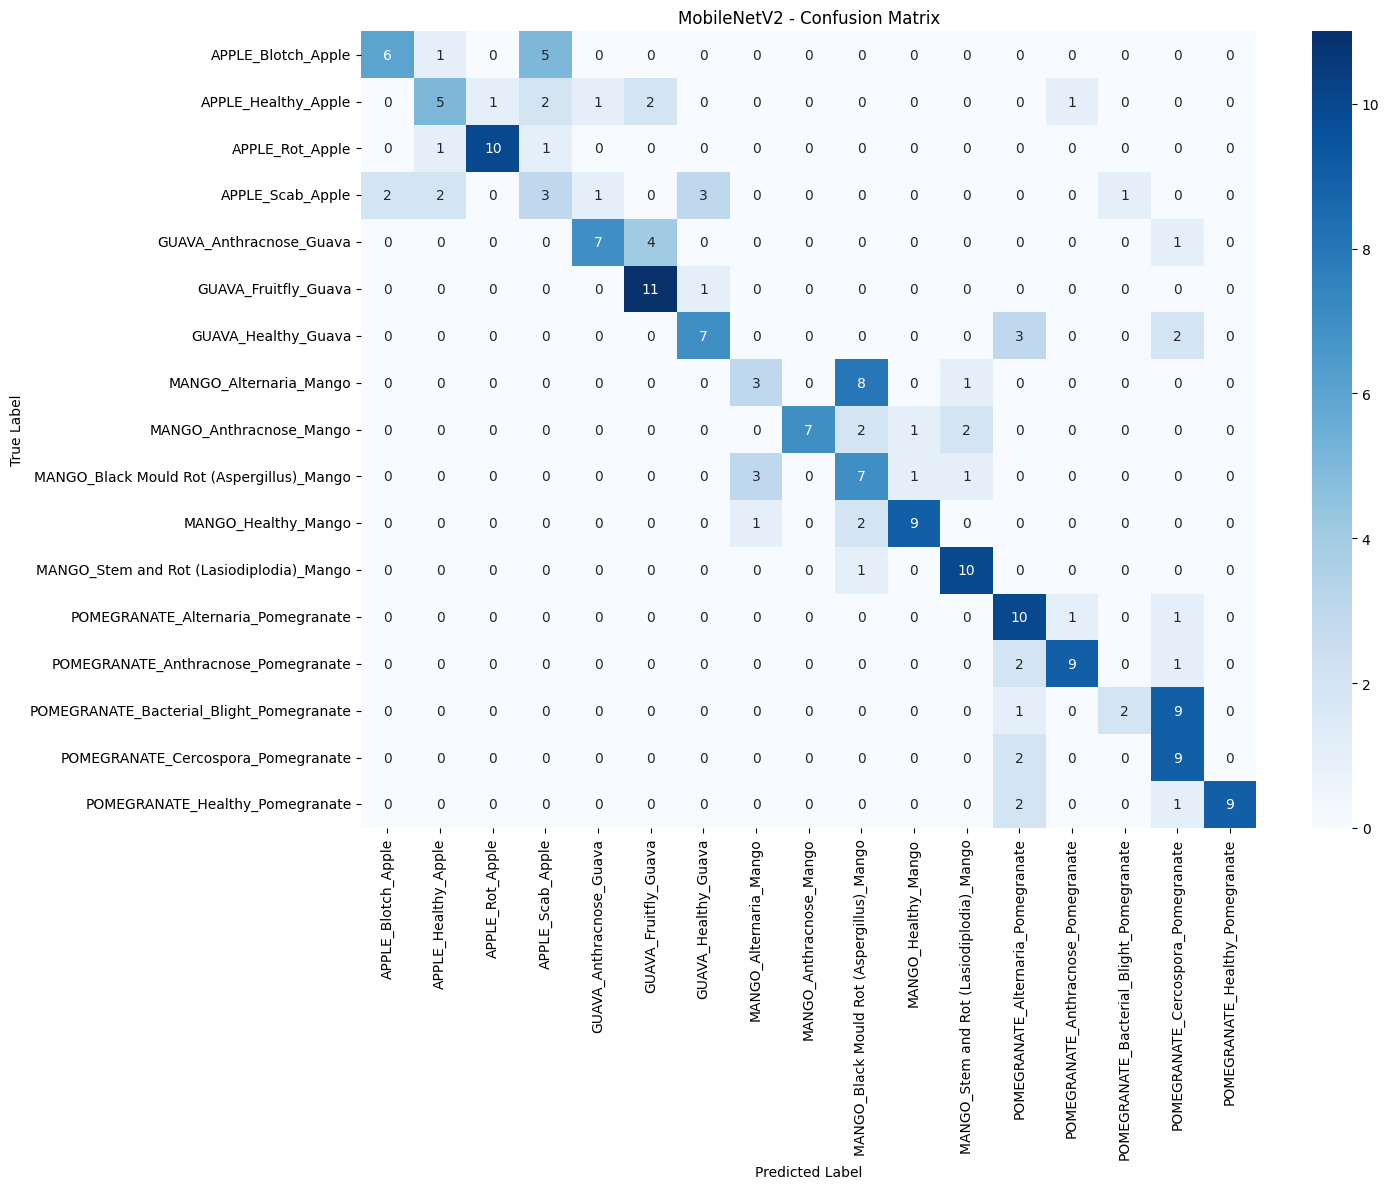

Model saved as models/MobileNetV2_final.keras
Results updated and saved to results/model_results.pkl

==== Training EfficientNetB0 ====
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.3510 - loss: 2.0042 - val_accuracy: 0.7761 - val_loss: 0.6047 - learning_rate: 0.0010
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 773ms/step - accuracy: 0.7722 - loss: 0.6647 - val_accuracy: 0.7960 - val_loss: 0.5506 - learning_rate: 0.0010
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 763ms/step - accuracy: 0.8190 - loss: 0.5504 - val_accuracy: 0.8507 - val_loss: 0.4517 - learning_rate: 0.0010
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 773ms/step - accuracy: 0.8416 - loss: 0.4538 - val_accuracy: 0.8507 - val_loss: 0.4340 - learning_rate: 0.0010
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 772ms/step - accuracy: 0.8578 - loss: 0.3790 - val_accuracy: 0.8458 - val_loss: 0.4207 - learning_rate: 0.0010
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 722ms/step - accuracy: 0.8866 - loss: 0.3361 - val_accuracy:

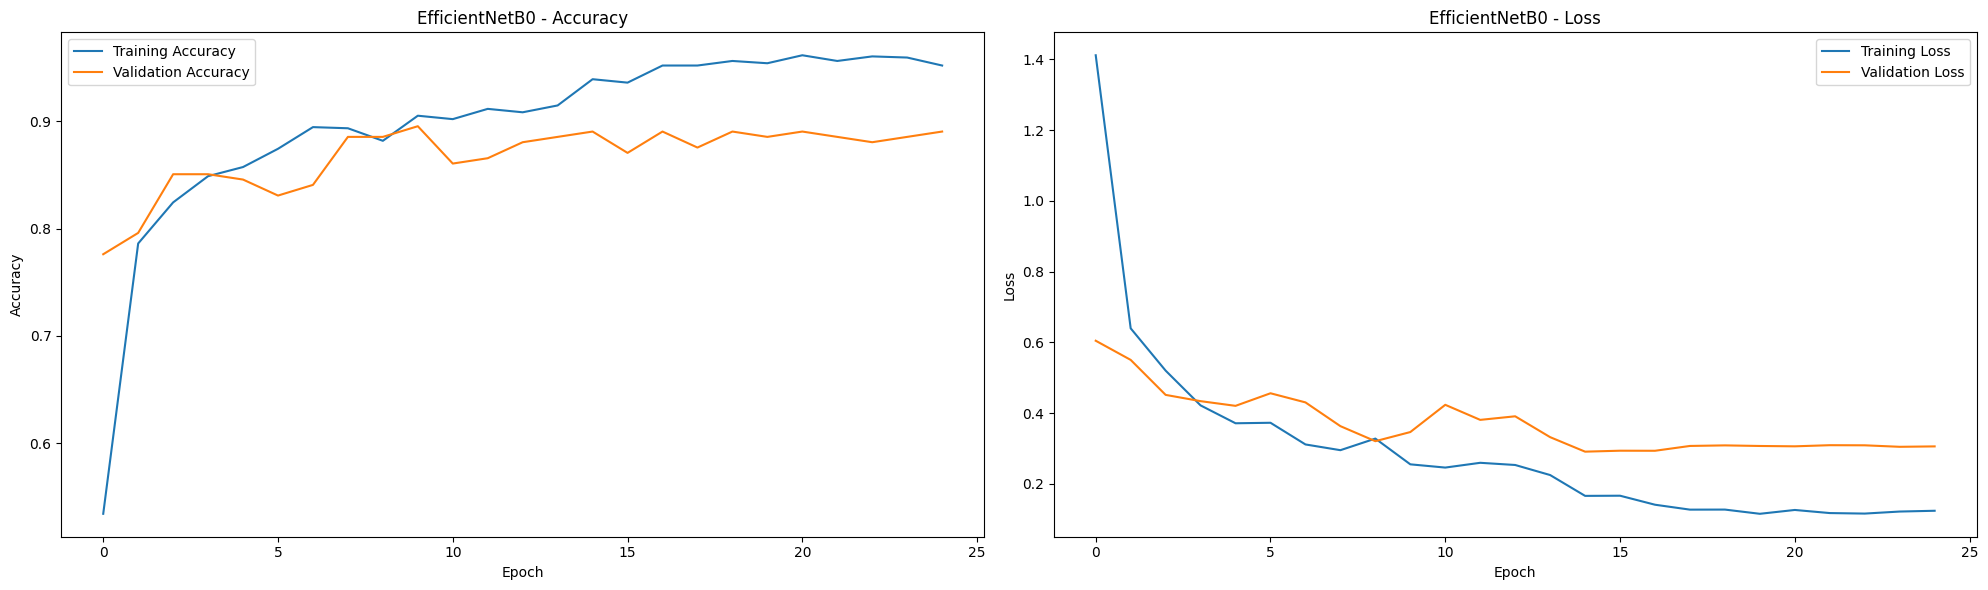


==== Evaluating EfficientNetB0 ====
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8772 - loss: 0.3468
Test accuracy: 0.8861
Test loss: 0.2999
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


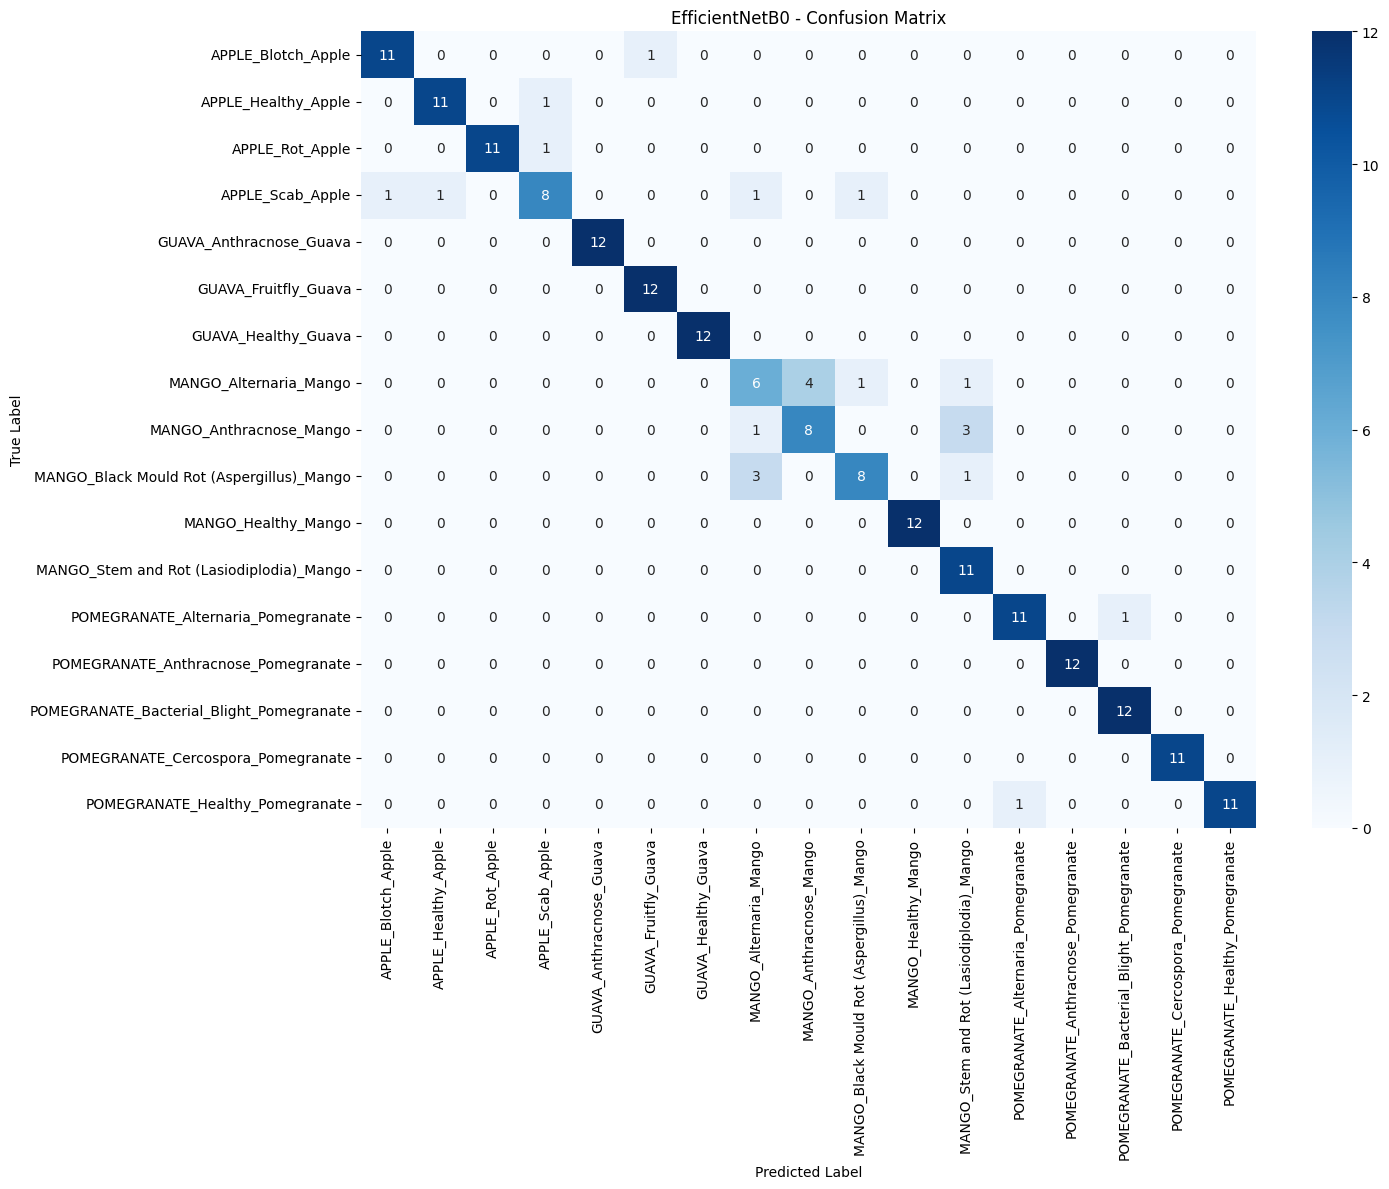

Model saved as models/EfficientNetB0_final.keras
Results updated and saved to results/model_results.pkl

==== Training ResNet50 ====
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.2639 - loss: 2.6275 - val_accuracy: 0.7562 - val_loss: 0.7912 - learning_rate: 0.0010
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 803ms/step - accuracy: 0.6694 - loss: 0.9776 - val_accuracy: 0.8259 - val_loss: 0.5195 - learning_rate: 0.0010
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 779ms/step - accuracy: 0.7441 - loss: 0.7344 - val_accuracy: 0.8308 - val_loss: 0.4652 - learning_rate: 0.0010
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 805ms/step - accuracy: 0.7911 - loss: 0.5848 - val_accuracy: 0.8358 - val_loss: 0.4463 - learning_rate: 0.0010
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 776ms/step - accuracy: 0.7827 - loss: 0.5798 - val_accuracy: 0.8806 - val_loss: 0.4009 - learning_rate: 0.0010
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 823ms/step - accuracy: 0.8006 - loss: 0.5948 - val_accuracy: 0.

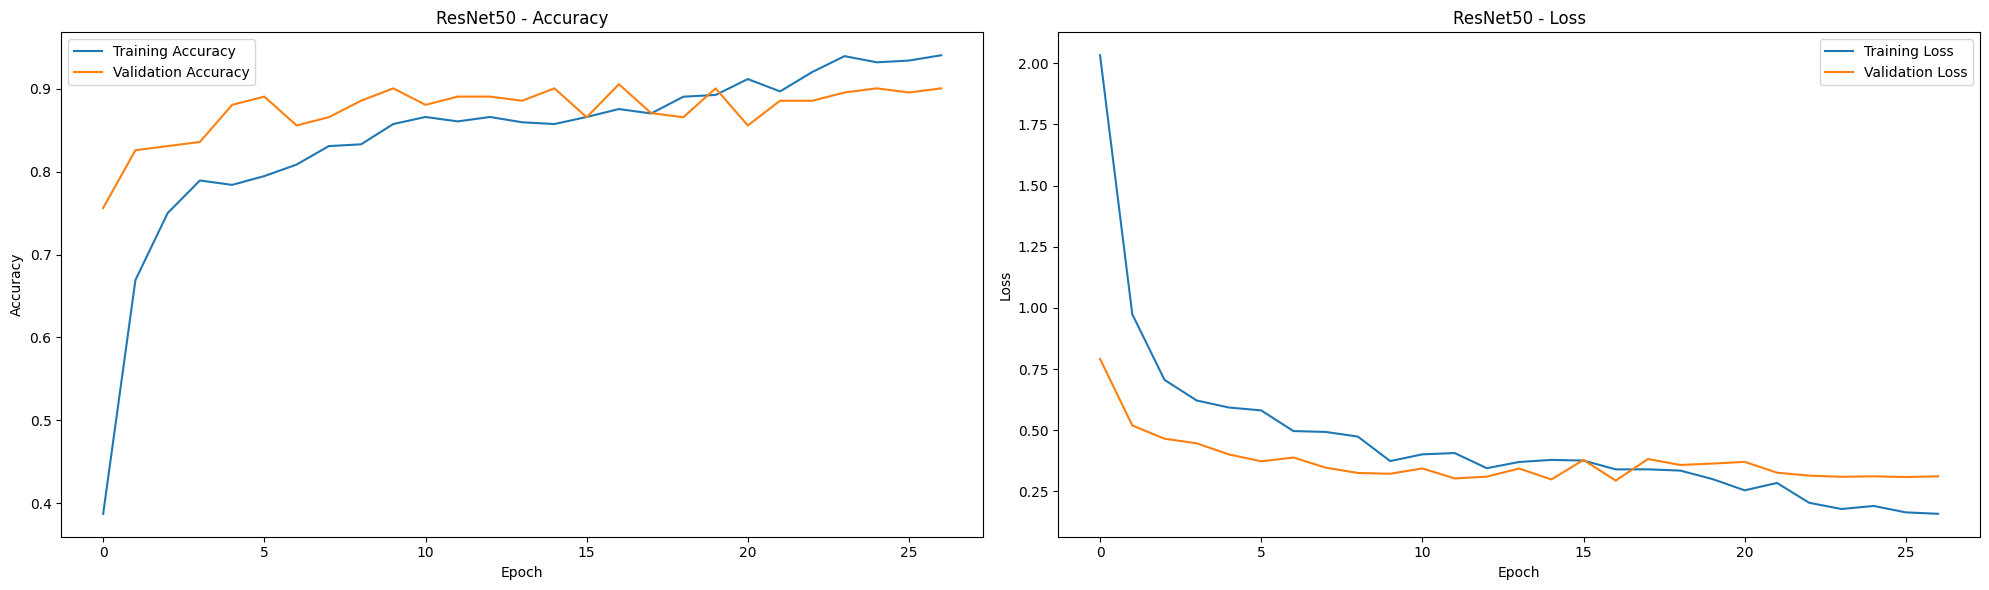


==== Evaluating ResNet50 ====
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 935ms/step - accuracy: 0.8354 - loss: 0.3836
Test accuracy: 0.8564
Test loss: 0.3510
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


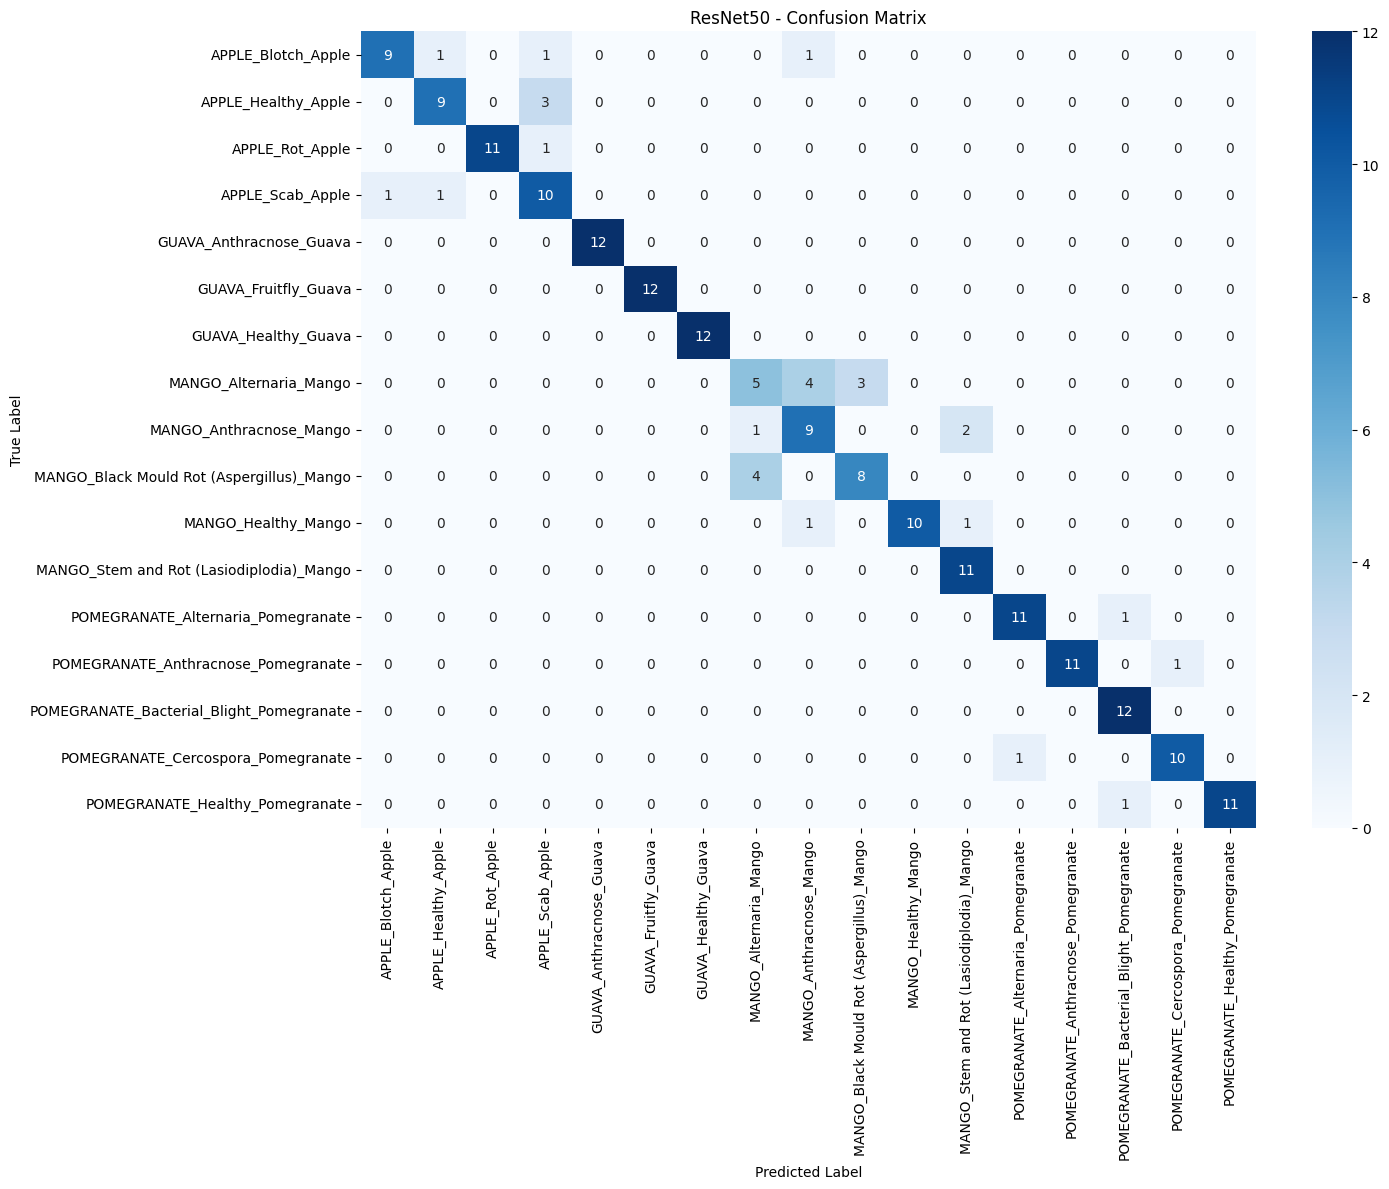

Model saved as models/ResNet50_final.keras
Results updated and saved to results/model_results.pkl


In [13]:
import os
import pickle

# Path to save the model results
results_path = "results/model_results.pkl"

# Create results directory if it doesn't exist
os.makedirs("results", exist_ok=True)

# Try loading existing results (optional)
if os.path.exists(results_path):
    with open(results_path, "rb") as f:
        model_results = pickle.load(f)
    print("Loaded existing model results.")
else:
    model_results = {}

# Train and evaluate each model
for model_name, model in models_to_train.items():
    if model_name in model_results:
        print(f"\nSkipping {model_name} — already trained and saved.")
        continue

    print(f"\n==== Training {model_name} ====")

    # Train the model
    trained_model, history = train_model(
        model,
        model_name,
        train_generator,
        validation_generator,
        epochs=EPOCHS
    )

    # Plot training history
    plot_training_history(history, model_name)

    # Evaluate the model
    print(f"\n==== Evaluating {model_name} ====")
    test_acc, report, cm = evaluate_model(trained_model, test_generator)

    # Plot confusion matrix
    plot_confusion_matrix(cm, list(test_generator.class_indices.keys()), model_name)

    # Store results
    model_results[model_name] = {
        'accuracy': test_acc,
        'report': report,
        'model': trained_model  # Note: this will be excluded from pickling
    }

    # Save the model separately
    trained_model.save(f"models/{model_name}_final.keras")
    print(f"Model saved as models/{model_name}_final.keras")

    # Save model results (excluding the model object itself, as Keras models can't be pickled)
    temp_results = {
        k: {key: val for key, val in v.items() if key != 'model'}
        for k, v in model_results.items()
    }

    with open(results_path, "wb") as f:
        pickle.dump(temp_results, f)
    print(f"Results updated and saved to {results_path}")


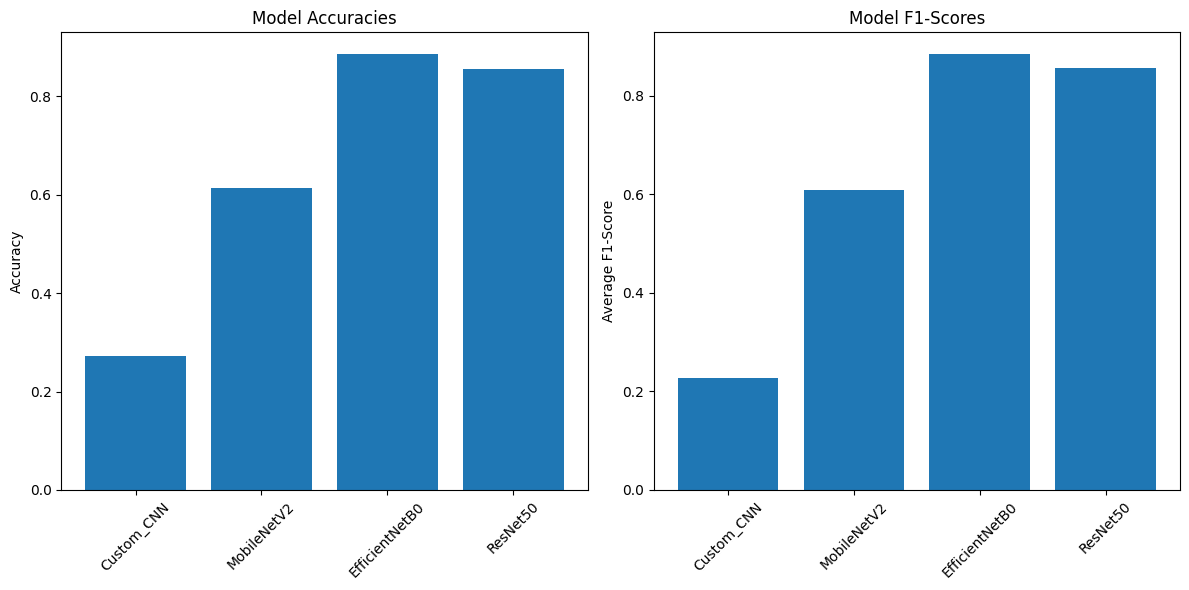


==== Model Comparison ====
Custom_CNN:
  Accuracy: 0.2723
  F1-Score: 0.2267
MobileNetV2:
  Accuracy: 0.6139
  F1-Score: 0.6094
EfficientNetB0:
  Accuracy: 0.8861
  F1-Score: 0.8848
ResNet50:
  Accuracy: 0.8564
  F1-Score: 0.8568

Best performing model: EfficientNetB0 with accuracy 0.8861


In [14]:
# Compare model performances
model_accuracies = {}
model_f1_scores = {}

for model_name, result in model_results.items():
    # Get accuracy
    model_accuracies[model_name] = result['accuracy']
    
    # Calculate average F1-score
    f1_scores = []
    for class_name, metrics in result['report'].items():
        if class_name not in ['accuracy', 'macro avg', 'weighted avg']:
            f1_scores.append(metrics['f1-score'])
    
    model_f1_scores[model_name] = np.mean(f1_scores)

# Create bar plots
plt.figure(figsize=(12, 6))

# Accuracy comparison
plt.subplot(1, 2, 1)
plt.bar(model_accuracies.keys(), model_accuracies.values())
plt.title('Model Accuracies')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)

# F1-score comparison
plt.subplot(1, 2, 2)
plt.bar(model_f1_scores.keys(), model_f1_scores.values())
plt.title('Model F1-Scores')
plt.ylabel('Average F1-Score')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Print detailed comparison
print("\n==== Model Comparison ====")
for model_name in model_results.keys():
    print(f"{model_name}:")
    print(f"  Accuracy: {model_accuracies[model_name]:.4f}")
    print(f"  F1-Score: {model_f1_scores[model_name]:.4f}")

# Find the best model
best_model_name = max(model_accuracies, key=model_accuracies.get)
print(f"\nBest performing model: {best_model_name} with accuracy {model_accuracies[best_model_name]:.4f}")

## Explainable AI (XAI) using Grad-CAM

In [15]:
# Cell 1: Import necessary libraries for Grad-CAM
import tensorflow as tf
import matplotlib.cm as cm
from IPython.display import Image, display
import cv2 # Make sure OpenCV is imported if not already

# Make sure necessary Keras components are available if running standalone
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras import Model # Explicitly import Model

# --- Add Preprocessing functions needed for the best model ---
# IMPORTANT: Make sure the preprocess_input function corresponding to your *best* model is imported
# Example: If EfficientNetB0 was best
# from tensorflow.keras.applications.efficientnet import preprocess_input as best_model_preprocess_input
# Example: If MobileNetV2 was best
# from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as best_model_preprocess_input
# Example: If ResNet50 was best
from tensorflow.keras.applications.resnet50 import preprocess_input as best_model_preprocess_input
# Example: If Custom_CNN was best, we'll define a simple rescale function
# def custom_cnn_preprocess_input(x):
#     return x / 255.0
# best_model_preprocess_input = custom_cnn_preprocess_input

print("Libraries for Grad-CAM imported.")
print(f"Using preprocess_input: {best_model_preprocess_input.__name__}") # Verify correct function

Libraries for Grad-CAM imported.
Using preprocess_input: preprocess_input


In [16]:
# Cell 2: Grad-CAM Helper Functions

def get_img_array(img_path, size):
    """Loads and preprocesses an image for model input, WITHOUT model-specific preprocessing yet."""
    img = load_img(img_path, target_size=size)
    array = img_to_array(img)
    # We return the array suitable for model-specific preprocessing later
    array = np.expand_dims(array, axis=0)
    return array

def make_gradcam_heatmap(img_array, model, base_model_layer_name, last_conv_layer_name, pred_index=None):
    """Generates the Grad-CAM heatmap, accessing layers within the base model."""

    # 1. Get the base model layer from the full model
    try:
        base_model_layer = model.get_layer(base_model_layer_name)
    except ValueError as e:
        print(f"ERROR: Could not find the base model layer named '{base_model_layer_name}' in the full model.")
        print(f"Full model layers: {[layer.name for layer in model.layers]}")
        raise e

    # 2. Create a model that maps the base model's input to the activations
    #    of the target conv layer AND the base model's output
    #    Note: This grad_model_base is relative to the BASE MODEL
    try:
         grad_model_base = Model(
             inputs=base_model_layer.inputs, # Input is the base model's input
             outputs=[base_model_layer.get_layer(last_conv_layer_name).output, # Target layer output
                      base_model_layer.output] # Output of the base model
         )
    except ValueError as e:
         print(f"ERROR: Could not find the target convolutional layer named '{last_conv_layer_name}' within the base model '{base_model_layer_name}'.")
         print(f"Base model ('{base_model_layer_name}') layers summary:")
         base_model_layer.summary() # Print summary again to help debug
         raise e

    # 3. Create a model that maps the full model's input to the final predictions
    #    This is needed to determine the top class index easily.
    full_pred_model = Model(inputs=model.inputs, outputs=model.output)

    # 4. Get the final predictions to find the class index
    final_preds = full_pred_model.predict(img_array)
    if pred_index is None:
        pred_index = tf.argmax(final_preds[0])

    # 5. Compute gradients using the full model structure, backpropagating
    #    to the output of the TARGET conv layer within the base model.
    #    We need the gradient of the FINAL prediction w.r.t the conv layer feature map.

    # Define a model specifically for gradient calculation: Full Input -> Target Layer Output
    # We use the *functional* base model layer we extracted earlier
    gradient_tape_model = Model(model.inputs, base_model_layer.get_layer(last_conv_layer_name).output)

    with tf.GradientTape() as tape:
        # Watch the input image
        tape.watch(img_array)
        # Get the output of the target convolutional layer
        target_layer_output = gradient_tape_model(img_array)
        # Ensure the tape tracks computations through the rest of the *full model* to the final prediction layer
        # We can do this by calculating the final preds inside the tape scope AFTER getting the target layer output
        # OR (simpler way): Define the model to output both target layer and final prediction

        # Model for tape: Full input -> [Target Layer Output, Final Prediction]
        tape_model_combined = Model(model.inputs, [gradient_tape_model.output, model.output])
        target_conv_output_tape, final_preds_tape = tape_model_combined(img_array)

        # Get the specific class channel from the final predictions
        class_channel = final_preds_tape[:, pred_index]

    # Gradient of the specified class score w.r.t. the feature map activations
    # NOTE: We take the gradient wrt the target layer's output obtained INSIDE the tape scope
    grads = tape.gradient(class_channel, target_conv_output_tape)

    # Handle potential None gradient if the layer is not connected or if it's from a non-trainable base frozen incorrectly.
    if grads is None:
          raise ValueError(f"Gradient computation failed. Grads is None. Check if layer '{last_conv_layer_name}' is connected correctly "
                           f"or if the model structure allows gradient flow to it from the final output. Is the base model trainable?")


    # Pool gradients over axes, leaving the channel axis
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weigh the feature map channels by the pooled gradients
    # Use the target layer output calculated outside the tape OR the one from inside
    # Let's use the one from the tape (`target_conv_output_tape`) for consistency
    heatmap = target_conv_output_tape[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize and ReLU
    heatmap = tf.maximum(heatmap, 0)
    max_val = tf.math.reduce_max(heatmap)
    if max_val == 0: # Avoid division by zero if heatmap is all zeros
        heatmap = tf.zeros(heatmap.shape)
        print("Warning: Grad-CAM heatmap generated all zeros.")
    else:
        heatmap = heatmap / max_val

    return heatmap.numpy()

# --- Keep save_and_display_gradcam function as before ---
def save_and_display_gradcam(img_path, heatmap, cam_path="cam.jpg", alpha=0.6):
    """Overlays heatmap on the original image and saves/displays it."""
    # Load the original image using OpenCV
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error: Could not read image at {img_path}")
        return None # Return None if image loading fails

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Convert to RGB

    # Resize heatmap to match the original image size
    try:
         # Use INTER_LINEAR for smoother resizing of the heatmap
         heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)
    except cv2.error as e:
         print(f"Error resizing heatmap: {e}. Heatmap shape: {heatmap.shape}, Image shape: {img.shape}")
         return None # Return None if resize fails

    # Convert heatmap to RGB colormap
    heatmap_normalized = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_normalized, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB) # Ensure RGB

    # Blend the heatmap
    superimposed_img = cv2.addWeighted(heatmap_colored, alpha, img, 1 - alpha, 0)
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

    # Display using matplotlib (inline in notebooks)
    plt.imshow(superimposed_img)
    plt.axis('off')
    # plt.savefig(cam_path) # Optional: Uncomment to save the image file

    # If you need to display using IPython.display specifically (less common now with inline plotting):
    # superimposed_img_bgr = cv2.cvtColor(superimposed_img, cv2.COLOR_RGB2BGR)
    # cv2.imwrite(cam_path, superimposed_img_bgr)
    # display(Image(filename=cam_path))

    return superimposed_img

# print("REVISED Grad-CAM helper functions defined.")

print("Grad-CAM helper functions defined.")

Grad-CAM helper functions defined.



Loading best model: models/ResNet50_final.keras


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_5           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 17)                  │           8,721 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31,482,805 (120.10 MB)

 Trainable params: 2,631,697 (10.04 MB)

...

 Optimizer params: 5,263,396 (20.08 MB)


Generating Grad-CAM for 5 samples using base 'resnet50' and target layer 'conv5_block3_out'...

Processing image: _0_161.png
ERROR processing Grad-CAM for _0_161.png: The layer sequential_6 has never been called and thus has no defined output.

Processing image: _0_18.png
ERROR processing Grad-CAM for _0_18.png: The layer sequential_6 has never been called and thus has no defined output.

Processing image: _0_379.png
ERROR processing Grad-CAM for _0_379.png: The layer sequential_6 has never been called and thus has no defined output.

Processing image: _0_396.png


Traceback (most recent call last):
  File "<ipython-input-17-c692bdd50e12>", line 107, in <cell line: 87>
    heatmap = make_gradcam_heatmap(
  File "<ipython-input-16-626a4fa1d90f>", line 39, in make_gradcam_heatmap
    full_pred_model = Model(inputs=model.inputs, outputs=model.output)
  File "/usr/local/lib/python3.10/dist-packages/keras/src/ops/operation.py", line 266, in output
    return self._get_node_attribute_at_index(0, "output_tensors", "output")
  File "/usr/local/lib/python3.10/dist-packages/keras/src/ops/operation.py", line 285, in _get_node_attribute_at_index
    raise ValueError(
ValueError: The layer sequential_6 has never been called and thus has no defined output.
Traceback (most recent call last):
  File "<ipython-input-17-c692bdd50e12>", line 107, in <cell line: 87>
    heatmap = make_gradcam_heatmap(
  File "<ipython-input-16-626a4fa1d90f>", line 39, in make_gradcam_heatmap
    full_pred_model = Model(inputs=model.inputs, outputs=model.output)
  File "/usr/local/li

ERROR processing Grad-CAM for _0_396.png: The layer sequential_6 has never been called and thus has no defined output.

Processing image: _0_41.png
ERROR processing Grad-CAM for _0_41.png: The layer sequential_6 has never been called and thus has no defined output.


Traceback (most recent call last):
  File "<ipython-input-17-c692bdd50e12>", line 107, in <cell line: 87>
    heatmap = make_gradcam_heatmap(
  File "<ipython-input-16-626a4fa1d90f>", line 39, in make_gradcam_heatmap
    full_pred_model = Model(inputs=model.inputs, outputs=model.output)
  File "/usr/local/lib/python3.10/dist-packages/keras/src/ops/operation.py", line 266, in output
    return self._get_node_attribute_at_index(0, "output_tensors", "output")
  File "/usr/local/lib/python3.10/dist-packages/keras/src/ops/operation.py", line 285, in _get_node_attribute_at_index
    raise ValueError(
ValueError: The layer sequential_6 has never been called and thus has no defined output.
Traceback (most recent call last):
  File "<ipython-input-17-c692bdd50e12>", line 107, in <cell line: 87>
    heatmap = make_gradcam_heatmap(
  File "<ipython-input-16-626a4fa1d90f>", line 39, in make_gradcam_heatmap
    full_pred_model = Model(inputs=model.inputs, outputs=model.output)
  File "/usr/local/li

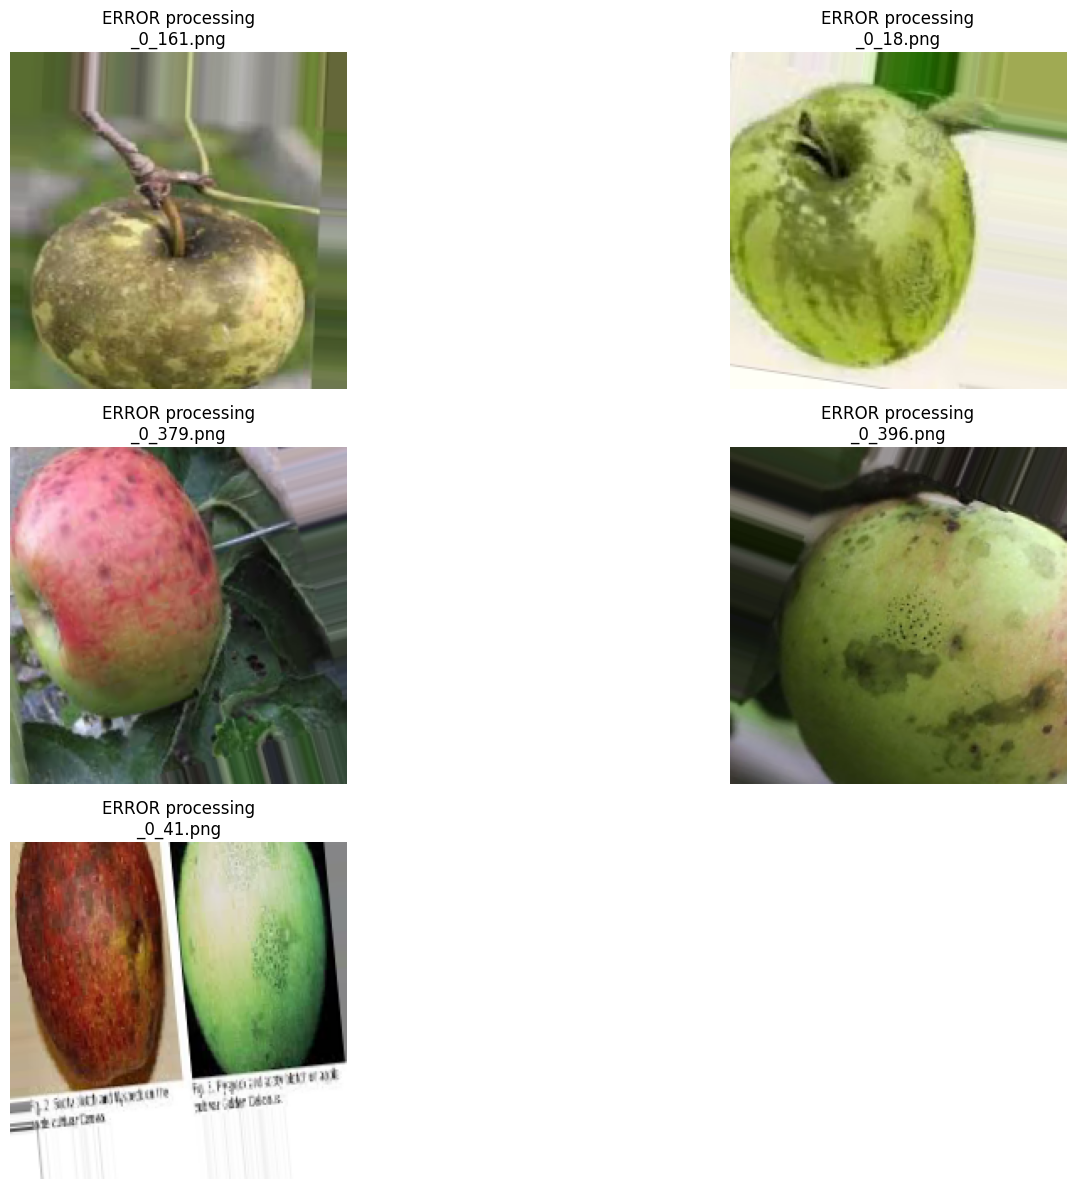

In [17]:
# Cell 3: Configure and Run Grad-CAM

# --- Configuration ---
# 1. Specify the name of the best performing model (must match the key in models_to_train/model_results)
#    !!!! UPDATE THIS BASED ON YOUR RESULTS !!!!
# --- Configuration --- (Ensure BEST_MODEL_NAME, BEST_MODEL_PATH are correct)
BEST_MODEL_NAME = 'ResNet50'
BEST_MODEL_PATH = 'models/ResNet50_final.keras' # Or the correct path
BASE_MODEL_LAYER_NAME_IN_SEQ = 'resnet50' # <-- Name of the base model layer in the outer Sequential model
LAST_CONV_LAYER_NAME = 'conv5_block3_out'  # <-- Name of target layer inside the base model

# 2. Specify the path to the SAVED best model file
if BEST_MODEL_NAME == 'Custom_CNN':
     BEST_MODEL_PATH = f"models/{BEST_MODEL_NAME}_final.keras"
else:
     # Use the fine-tuned path if applicable for transfer models
     finetuned_path = f"models/{BEST_MODEL_NAME}_final_finetuned.keras"
     basic_path = f"models/{BEST_MODEL_NAME}_final.keras"
     # Check if the fine-tuned version exists
     if os.path.exists(finetuned_path):
         BEST_MODEL_PATH = finetuned_path
     else:
          BEST_MODEL_PATH = basic_path
          print(f"Warning: Fine-tuned model '{finetuned_path}' not found, using '{basic_path}'. Fine-tuning might not have run or saved correctly.")

# 3. Specify the name of the LAST convolutional layer in the BEST model
#    !!!! FIND THIS USING model.summary() and UPDATE !!!!
#    Examples (these might change based on Keras/TF versions or your custom head):
#      - EfficientNetB0: 'top_conv' or 'block7a_project_conv' / 'block7a_se_excite' might work
#      - MobileNetV2: 'out_relu' or 'block_16_project_conv' / 'block_16_depthwise_relu'
#      - ResNet50: 'conv5_block3_out' or similar layer before GlobalAveragePooling
#      - Custom_CNN: The name of your last Conv2D layer (e.g., 'conv2d_3')
LAST_CONV_LAYER_NAME = 'conv5_block3_out' # <-- UPDATE THIS FOR YOUR BEST MODEL

# 4. Image size (must match model input)
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# 5. Select some sample images from the test set for visualization
NUM_SAMPLES_TO_VISUALIZE = 5
test_generator.reset() # Ensure generator starts from the beginning
sample_img_paths = []
sample_true_labels = []
count = 0
stop = False
# Get file paths and labels directly from the generator
for i in range(len(test_generator)):
     batch_x, batch_y = test_generator[i]
     batch_indices = test_generator.index_array[i * test_generator.batch_size : (i + 1) * test_generator.batch_size]
     if not len(batch_indices): # Handle potential last batch issue if index_array runs short
        break
     batch_files = [test_generator.filepaths[idx] for idx in batch_indices]

     for filepath, label_vec in zip(batch_files, batch_y):
          sample_img_paths.append(filepath)
          sample_true_labels.append(np.argmax(label_vec))
          count += 1
          if count >= NUM_SAMPLES_TO_VISUALIZE:
               stop = True
               break
     if stop:
          break

# --- Load Model ---
print(f"\nLoading best model: {BEST_MODEL_PATH}")
try:
    model = load_model(BEST_MODEL_PATH)
    model.summary() # Print summary to help find the LAST_CONV_LAYER_NAME
        # ----> ADD THESE LINES <----
    # Access the base model (the first layer, named 'resnet50' in your summary)
    # base_model_layer = model.get_layer('resnet50') # Use the name from the summary
    # print("\n--- Summary of the Base Model Layer ('resnet50') ---")
    # base_model_layer.summary() # Print the summary of the layers INSIDE ResNet50
    # print("--- End of Base Model Layer Summary ---")
    # ----> END OF ADDED LINES <----
except Exception as e:
    print(f"Error loading model: {e}")
    print("Ensure the BEST_MODEL_PATH is correct and the model file is not corrupted.")
    # You might need to re-run the training if the model wasn't saved.
    raise # Stop execution if model can't be loaded

# --- Generate and Display Grad-CAM (Revised Loop) ---
print(f"\nGenerating Grad-CAM for {len(sample_img_paths)} samples using base '{BASE_MODEL_LAYER_NAME_IN_SEQ}' and target layer '{LAST_CONV_LAYER_NAME}'...")
# ... (rest of setup before the loop) ...

plt.figure(figsize=(16, 4 * ((NUM_SAMPLES_TO_VISUALIZE + 1) // 2))) # Adjust figure size

if not sample_img_paths:
     print("No samples found to visualize.")
else:
    for i, (img_path, true_label_idx) in enumerate(zip(sample_img_paths, sample_true_labels)):
        print(f"\nProcessing image: {os.path.basename(img_path)}")
        try:
            # ... (1. Load image, 2. Resize/prepare, 3. Preprocess) ...
            # --- Make sure steps 1-3 from the previous code block are here ---
            img_array_orig_uint8 = cv2.imread(img_path)
            if img_array_orig_uint8 is None: raise FileNotFoundError(f"Could not read {img_path}")
            img_array_orig_rgb = cv2.cvtColor(img_array_orig_uint8, cv2.COLOR_BGR2RGB)
            img_resized = tf.image.resize(img_array_orig_rgb, IMG_SIZE)
            img_array_input = np.expand_dims(img_resized, axis=0)
            img_array_processed = best_model_preprocess_input(img_array_input.copy()) # Ensure this uses resnet50 preprocess

            # --- Step 4. Predict remains same ---
            preds = model.predict(img_array_processed, verbose=0) # Use verbose=0 to reduce output noise
            predicted_label_idx = np.argmax(preds[0])

            # --- Step 5. Generate heatmap (use the REVISED function call) ---
            heatmap = make_gradcam_heatmap(
                img_array_processed,        # Processed image array
                model,                      # The FULL sequential model
                BASE_MODEL_LAYER_NAME_IN_SEQ, # Name of base layer in sequential ('resnet50')
                LAST_CONV_LAYER_NAME,       # Name of target layer inside base ('conv5_block3_out')
                pred_index=predicted_label_idx
            )

            # --- Step 6. Display ---
            plt.subplot((NUM_SAMPLES_TO_VISUALIZE + 1) // 2, 2, i + 1)
            true_class_name = idx_to_class.get(true_label_idx, f'Unknown Index {true_label_idx}')
            pred_class_name = idx_to_class.get(predicted_label_idx, f'Unknown Index {predicted_label_idx}')
            plt.title(f"True: {true_class_name}\nPred: {pred_class_name} ({preds[0][predicted_label_idx]:.2f})")

            save_and_display_gradcam(img_path, heatmap, alpha=0.6)

        except Exception as e:
            print(f"ERROR processing Grad-CAM for {os.path.basename(img_path)}: {e}")
            import traceback
            traceback.print_exc() # Print detailed traceback for debugging
            # Attempt to display original image on error
            try:
                 plt.subplot((NUM_SAMPLES_TO_VISUALIZE + 1) // 2, 2, i + 1)
                 plt.imshow(img_array_orig_rgb)
                 plt.title(f"ERROR processing\n{os.path.basename(img_path)}")
                 plt.axis('off')
            except:
                 pass
            continue # Continue to the next image

    plt.tight_layout()
    plt.show()

In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, History

def train_model_with_finetuning(model, base_model, model_name, train_gen, val_gen,
                                initial_epochs=10, fine_tune_epochs=10,
                                initial_lr=0.001, fine_tune_lr=0.0001,
                                fine_tune_at_percentage=0.15): # Percentage of layers to unfreeze from the end
    """
    Trains the model in two phases:
    1. Initial phase: Only train the classifier head (base model frozen).
    2. Fine-tuning phase: Unfreeze some top layers of the base model and train with a lower LR.
    """
    history_full = History()
    history_full.history = {} # Initialize history dict

    # --- Phase 1: Train the Head ---
    print(f"\n--- Phase 1: Training Head for {model_name} ---")
    print(f"Epochs: {initial_epochs}, LR: {initial_lr}")
    base_model.trainable = False # Ensure base is frozen

    model.compile(
        optimizer=Adam(learning_rate=initial_lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    checkpoint_path = f"models/{model_name}_phase1_best.keras"
    callbacks_phase1 = [
        # ReduceLROnPlateau during head training might help if it plateaus early
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1),
        ModelCheckpoint(filepath=checkpoint_path, monitor='val_accuracy', save_best_only=True, mode='max', verbose=0), # Less verbose checkpoint
        # Early stopping for phase 1 if it clearly diverges or stops improving significantly
        EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1) # Longer patience
    ]

    history_phase1 = model.fit(
        train_gen,
        epochs=initial_epochs,
        validation_data=val_gen,
        callbacks=callbacks_phase1
    )
    # Combine history
    for key, val in history_phase1.history.items():
        history_full.history[key] = val

    # Load best weights from phase 1
    print(f"Loading best weights from Phase 1 checkpoint: {checkpoint_path}")
    model.load_weights(checkpoint_path)

    # --- Phase 2: Fine-Tuning ---
    print(f"\n--- Phase 2: Fine-Tuning {model_name} ---")
    print(f"Epochs: {fine_tune_epochs}, LR: {fine_tune_lr}")

    # Determine number of layers to unfreeze
    total_layers = len(base_model.layers)
    fine_tune_at_layer_index = int(total_layers * (1 - fine_tune_at_percentage))
    if fine_tune_at_layer_index < 0 : fine_tune_at_layer_index = 0 # Ensure non-negative

    print(f"Base model total layers: {total_layers}")
    print(f"Unfreezing from layer index: {fine_tune_at_layer_index} onwards.")

    base_model.trainable = True
    for layer in base_model.layers[:fine_tune_at_layer_index]:
        layer.trainable = False
    # Ensure BatchNormalization layers remain in inference mode if they were frozen during phase 1
    # This prevents their internal statistics from being updated wildly with the low LR
    for layer in base_model.layers:
         if isinstance(layer, layers.BatchNormalization) and not layer.trainable:
              layer.trainable = False # Explicitly keep frozen BN layers frozen


    # Re-compile the model with a lower learning rate for fine-tuning
    model.compile(
        optimizer=Adam(learning_rate=fine_tune_lr), # Use the very low learning rate
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\nModel Summary after Unfreezing for Fine-Tuning:")
    model.summary() # Show which layers are now trainable
    num_trainable_params = sum([np.prod(w.shape) for w in model.trainable_weights])
    print(f"Number of trainable parameters for fine-tuning: {num_trainable_params}")


    checkpoint_path_ft = f"models/{model_name}_finetune_best.keras"
    callbacks_phase2 = [
        ModelCheckpoint(filepath=checkpoint_path_ft, monitor='val_accuracy', save_best_only=True, mode='max', verbose=0), # Save best fine-tuned weights
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=4, min_lr=1e-7, verbose=1), # Slower decay, lower min_lr
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1) # Generous patience for fine-tuning
    ]

    # Calculate the total number of epochs already completed
    initial_epoch_count = len(history_full.history.get('loss', [])) # Get actual epochs run in phase 1

    history_phase2 = model.fit(
        train_gen,
        epochs=initial_epoch_count + fine_tune_epochs, # Continue epoch numbering
        initial_epoch=initial_epoch_count,      # Start from the last epoch of phase 1
        validation_data=val_gen,
        callbacks=callbacks_phase2
    )

    # Combine history
    for key, val in history_phase2.history.items():
        if key in history_full.history:
            history_full.history[key].extend(val)
        else:
            history_full.history[key] = val

    # Load the best weights found during fine-tuning
    print(f"Loading best weights from Fine-Tuning checkpoint: {checkpoint_path_ft}")
    model.load_weights(checkpoint_path_ft)


    return model, history_full


==================== Training Custom_CNN ====================
Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 36s 882ms/step - accuracy: 0.2269 - loss: 2.0626 - val_accuracy: 0.3682 - val_loss: 1.8515 - learning_rate: 0.0010
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 799ms/step - accuracy: 0.2648 - loss: 1.9858 - val_accuracy: 0.4129 - val_loss: 1.7360 - learning_rate: 0.0010
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 758ms/step - accuracy: 0.2841 - loss: 1.9807 - val_accuracy: 0.3035 - val_loss: 1.8560 - learning_rate: 0.0010
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 744ms/step - accuracy: 0.2949 - loss: 1.9292 - val_accuracy: 0.2985 - val_loss: 1.8339 - learning_rate: 0.0010
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 759ms/step - accuracy: 0.3242 - loss: 1.8312 - val_accuracy: 0.3234 - val_loss: 1.8270 - learning_rate: 0.0010
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 736ms/step - accuracy: 0.3658 - loss: 1.7743 - val_accuracy: 0.3483 - val_loss: 1.8129 - learning_rate: 0.0010
Epoch 7/25
30/30 ━━

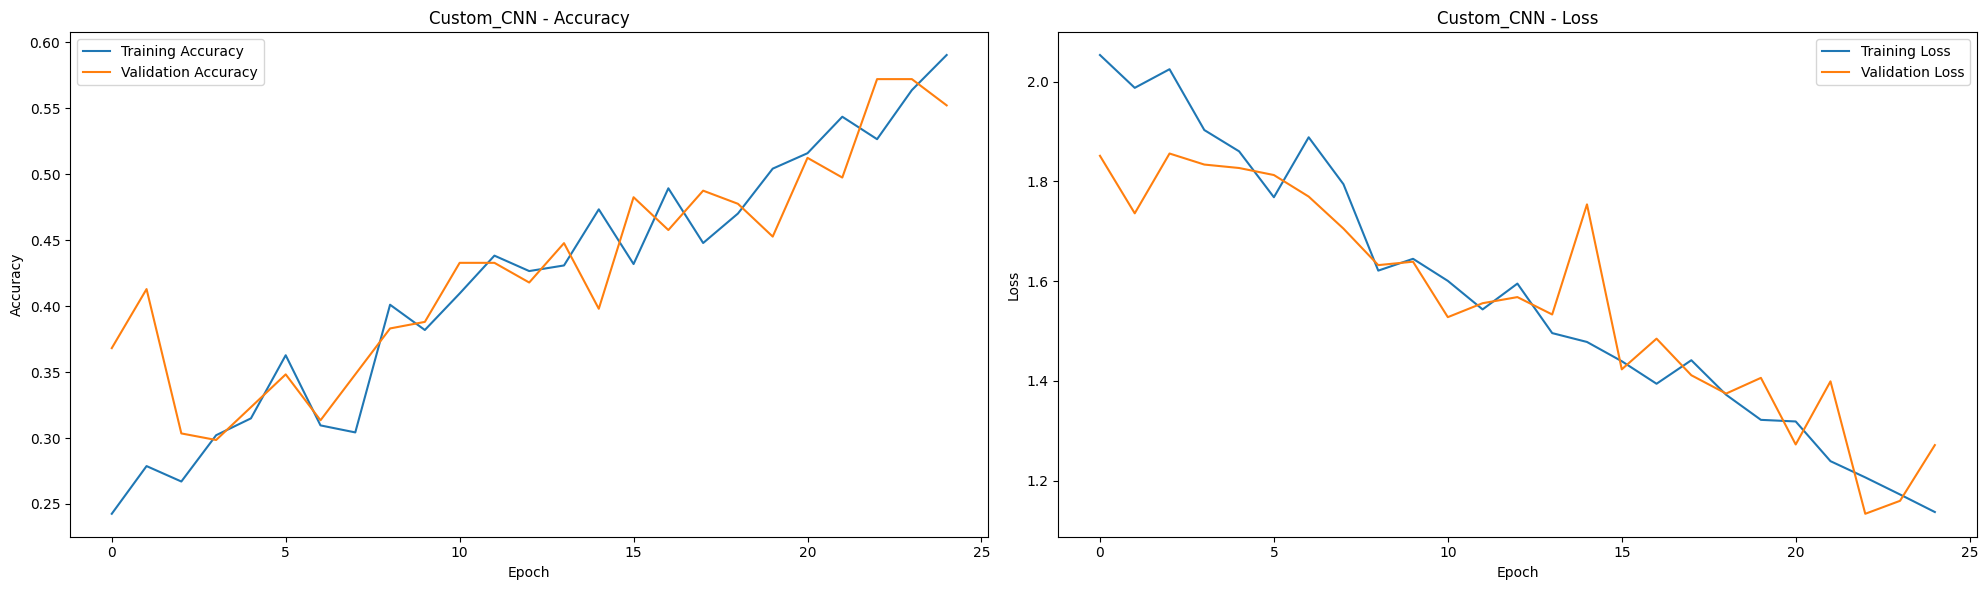


==================== Evaluating Custom_CNN ====================
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 557ms/step - accuracy: 0.5754 - loss: 1.2464
Test accuracy: 0.6485
Test loss: 1.0483
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step


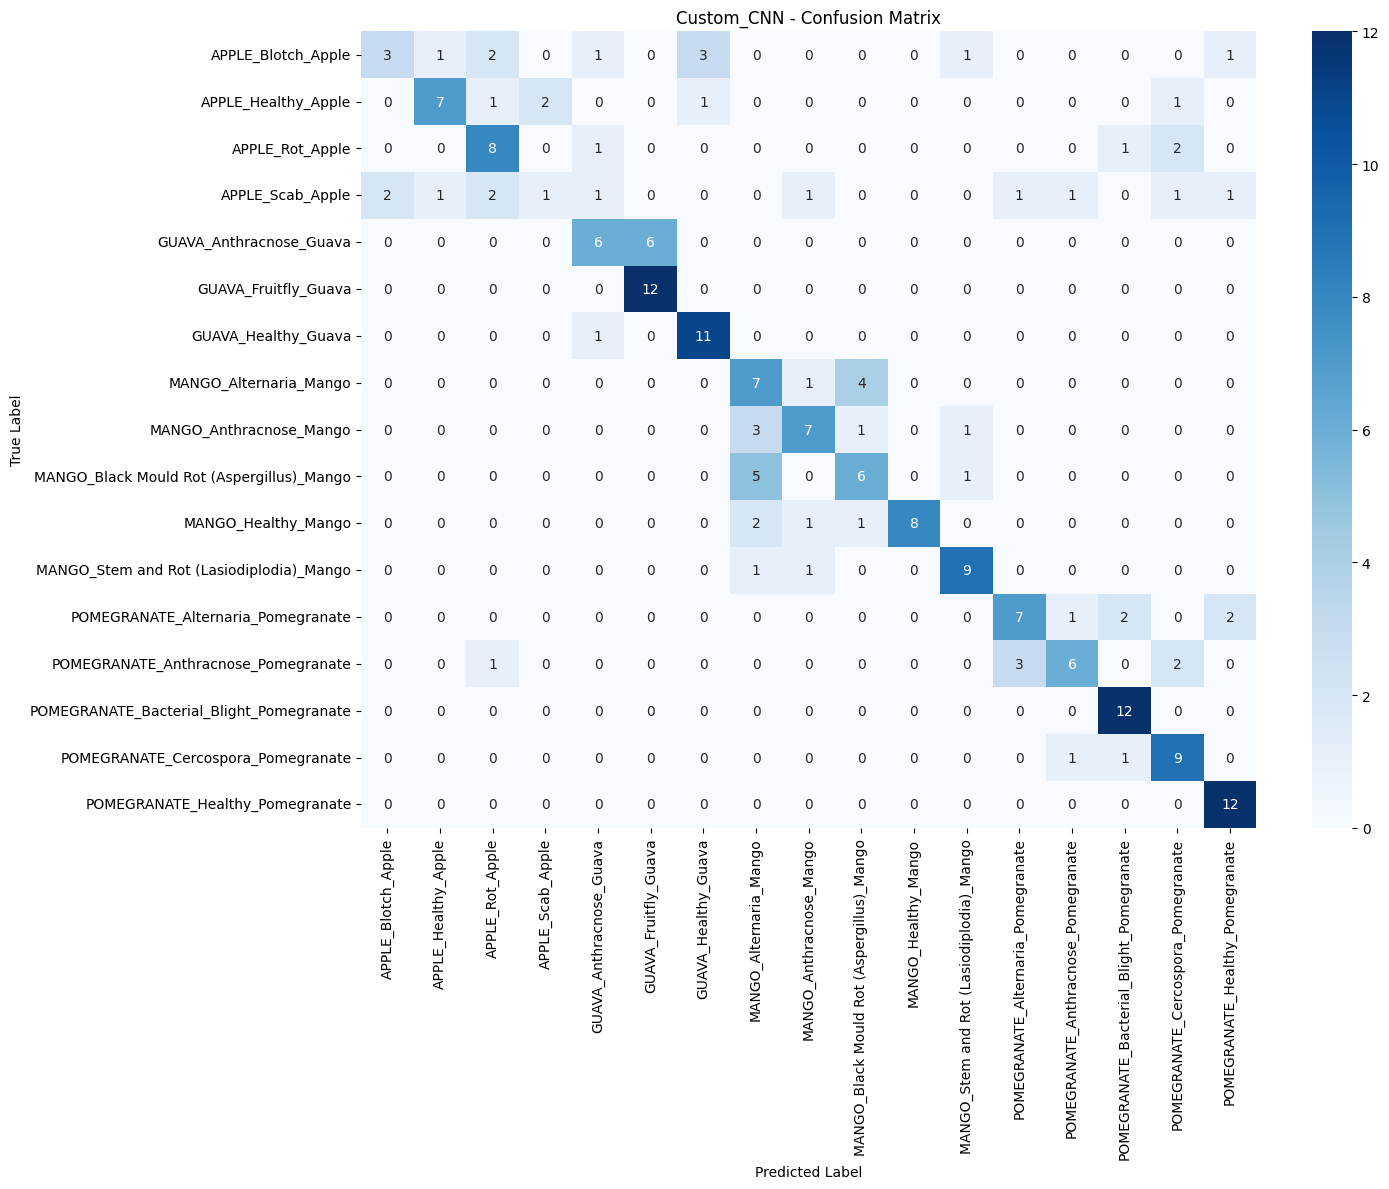

Final model saved as models/Custom_CNN_final.keras

==================== Training MobileNetV2 ====================

--- Phase 1: Training Head for MobileNetV2 ---
Epochs: 20, LR: 0.001
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 40s 925ms/step - accuracy: 0.6308 - loss: 0.9472 - val_accuracy: 0.6070 - val_loss: 1.0463 - learning_rate: 0.0010
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 757ms/step - accuracy: 0.6078 - loss: 0.9761 - val_accuracy: 0.6020 - val_loss: 1.0976 - learning_rate: 0.0010
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 771ms/step - accuracy: 0.5976 - loss: 1.0261 - val_accuracy: 0.6119 - val_loss: 0.9558 - learning_rate: 0.0010
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 748ms/step - accuracy: 0.6615 - loss: 0.8673 - val_accuracy: 0.5572 - val_loss: 1.1752 - learning_rate: 0.0010
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 735ms/step - accuracy: 0.6260 - loss: 0.9384 - val_accuracy: 0.5672 - val_loss: 1.0283 - learning_rate: 0.0010
Epoch 6/20
29/30 ━━━━━━━━━━━━━━━━━━━━ 0s 628ms/ste

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1024)                │       1,311,744 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 17)                  │           8,721 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,103,249 (15.65 MB)

 Trainable params: 3,205,265 (12.23 MB)

 Non-trainable params: 897,984 (3.43 MB)

Number of trainable parameters for fine-tuning: 3205265
Epoch 11/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.2967 - loss: 3.0195 - val_accuracy: 0.4925 - val_loss: 1.7894 - learning_rate: 1.0000e-04
Epoch 12/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 754ms/step - accuracy: 0.5352 - loss: 1.3237 - val_accuracy: 0.5373 - val_loss: 1.5889 - learning_rate: 1.0000e-04
Epoch 13/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 782ms/step - accuracy: 0.6044 - loss: 1.0330 - val_accuracy: 0.5721 - val_loss: 1.6735 - learning_rate: 1.0000e-04
Epoch 14/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 757ms/step - accuracy: 0.6565 - loss: 0.9205 - val_accuracy: 0.6070 - val_loss: 1.2983 - learning_rate: 1.0000e-04
Epoch 15/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 723ms/step - accuracy: 0.6614 - loss: 0.8360 - val_accuracy: 0.5721 - val_loss: 1.6340 - learning_rate: 1.0000e-04
Epoch 16/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 751ms/step - accuracy: 0.7078 - loss: 0.8209 - val_accuracy: 0.6020 - val_loss: 1.5384 - learning_rate: 1.0000e-04

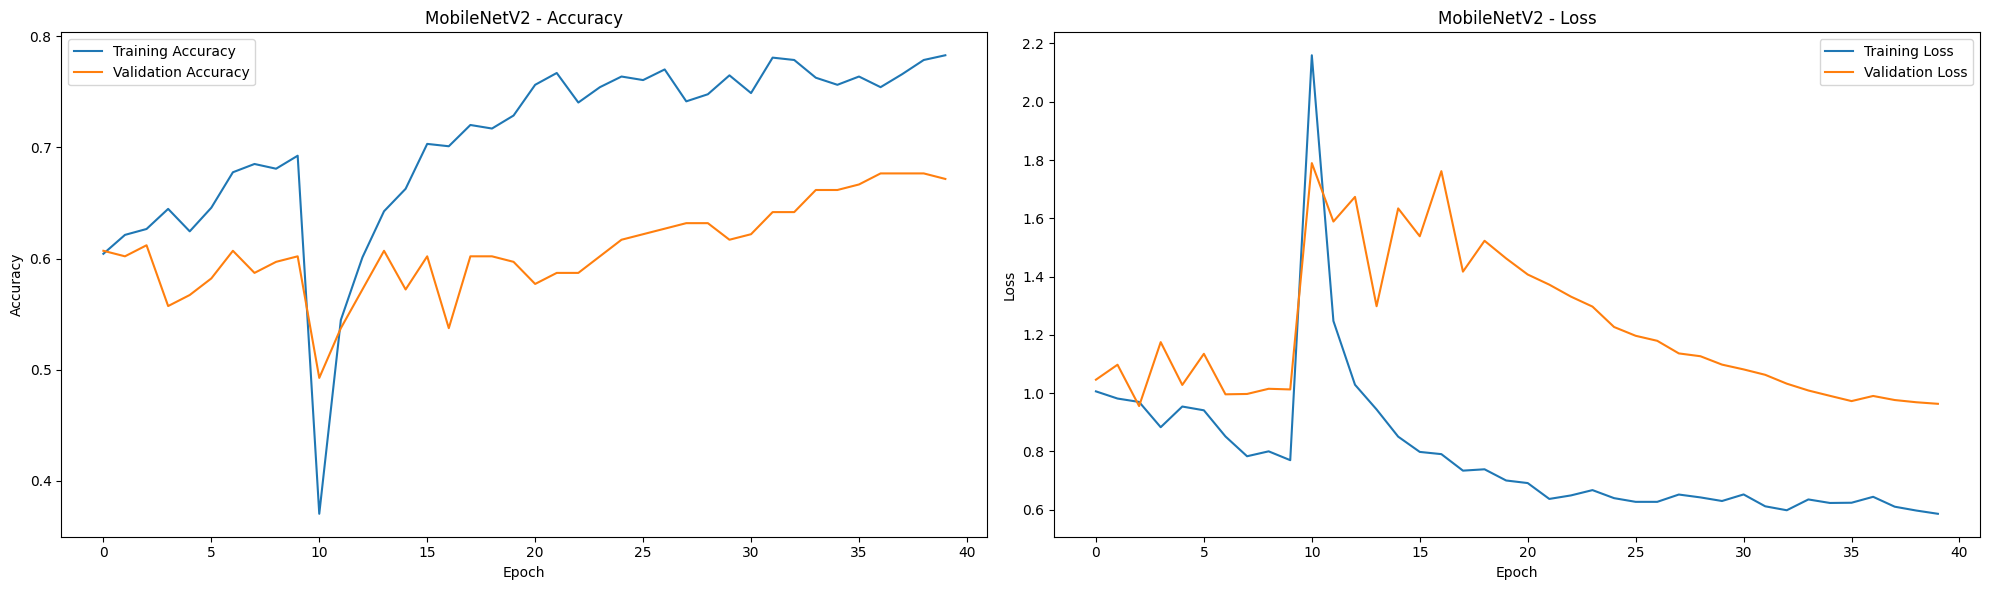


==================== Evaluating MobileNetV2 ====================
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 691ms/step - accuracy: 0.6486 - loss: 0.9685
Test accuracy: 0.6733
Test loss: 0.8774
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


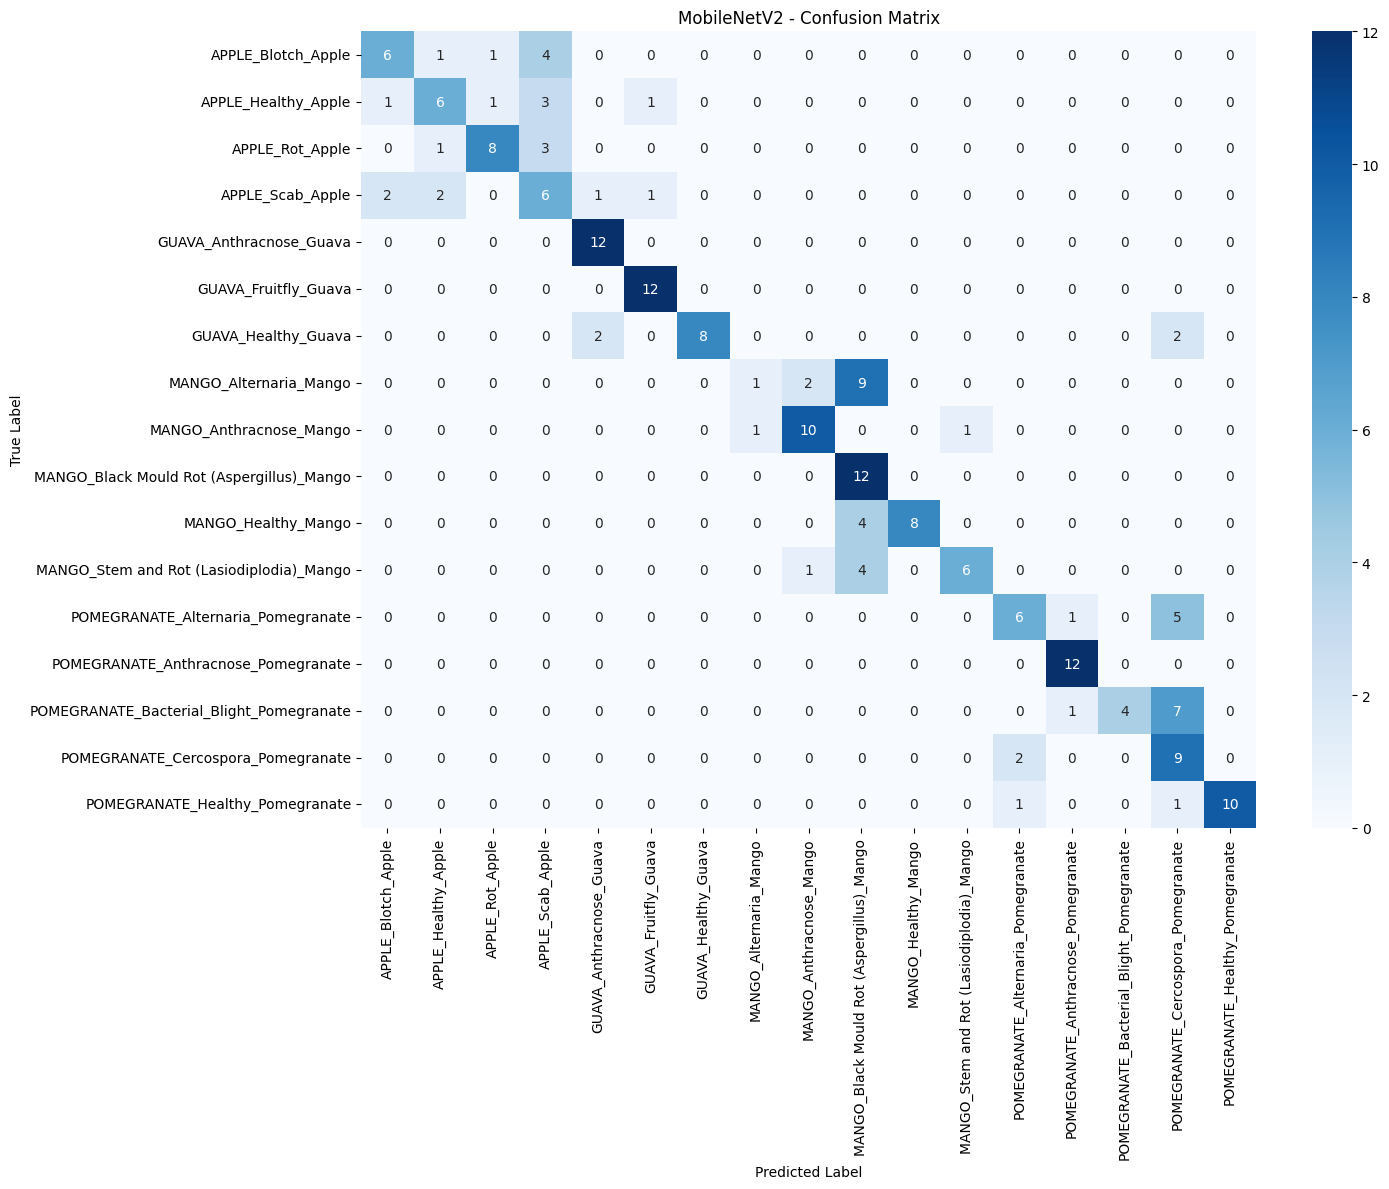

Final model saved as models/MobileNetV2_final_finetuned.keras

==================== Training EfficientNetB0 ====================

--- Phase 1: Training Head for EfficientNetB0 ---
Epochs: 20, LR: 0.001
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.9191 - loss: 0.2053 - val_accuracy: 0.8507 - val_loss: 0.5424 - learning_rate: 0.0010
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 765ms/step - accuracy: 0.8845 - loss: 0.3490 - val_accuracy: 0.8806 - val_loss: 0.3548 - learning_rate: 0.0010
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 747ms/step - accuracy: 0.8998 - loss: 0.2593 - val_accuracy: 0.8806 - val_loss: 0.3872 - learning_rate: 0.0010
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 772ms/step - accuracy: 0.9339 - loss: 0.1957 - val_accuracy: 0.8706 - val_loss: 0.3710 - learning_rate: 0.0010
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 31s 809ms/step - accuracy: 0.9321 - loss: 0.2238 - val_accuracy: 0.8856 - val_loss: 0.3319 - learning_rate: 0.0010
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_4           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 1024)                │       1,311,744 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 17)                  │           8,721 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,894,836 (22.49 MB)

 Trainable params: 3,784,177 (14.44 MB)

 Non-trainable params: 2,110,659 (8.05 MB)

Number of trainable parameters for fine-tuning: 3784177
Epoch 18/47
30/30 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.8267 - loss: 0.6139 - val_accuracy: 0.8657 - val_loss: 0.4078 - learning_rate: 1.0000e-04
Epoch 19/47
30/30 ━━━━━━━━━━━━━━━━━━━━ 32s 793ms/step - accuracy: 0.9145 - loss: 0.2362 - val_accuracy: 0.8856 - val_loss: 0.3634 - learning_rate: 1.0000e-04
Epoch 20/47
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 768ms/step - accuracy: 0.9280 - loss: 0.2154 - val_accuracy: 0.8856 - val_loss: 0.3533 - learning_rate: 1.0000e-04
Epoch 21/47
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 744ms/step - accuracy: 0.9420 - loss: 0.1515 - val_accuracy: 0.8856 - val_loss: 0.3488 - learning_rate: 1.0000e-04
Epoch 22/47
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 786ms/step - accuracy: 0.9354 - loss: 0.1606 - val_accuracy: 0.9005 - val_loss: 0.4085 - learning_rate: 1.0000e-04
Epoch 23/47
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 796ms/step - accuracy: 0.9457 - loss: 0.1320 - val_accuracy: 0.8756 - val_loss: 0.3825 - learning_rate: 1.0000e-04

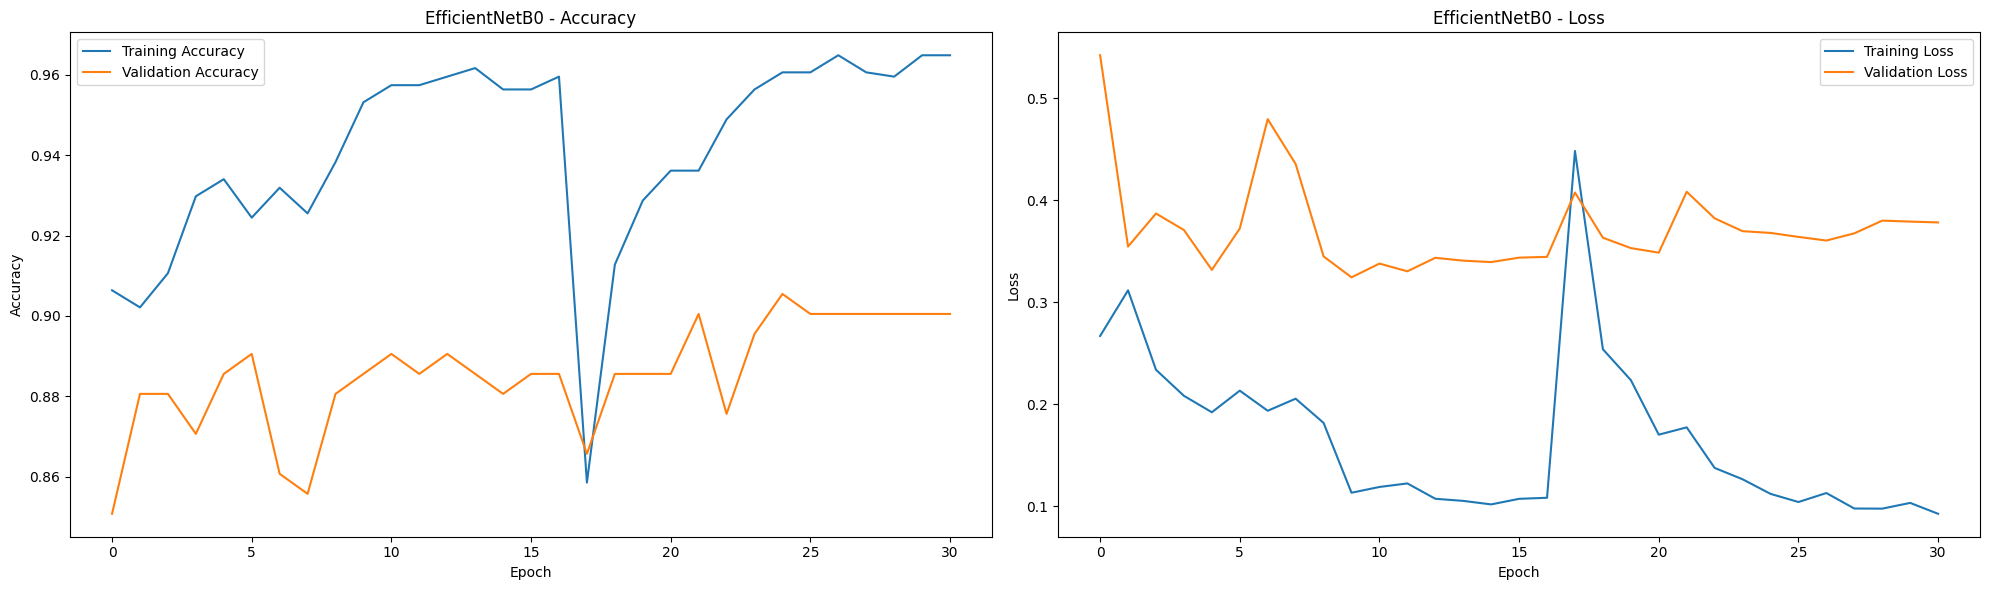


==================== Evaluating EfficientNetB0 ====================
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.9023 - loss: 0.3039
Test accuracy: 0.9059
Test loss: 0.2606
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


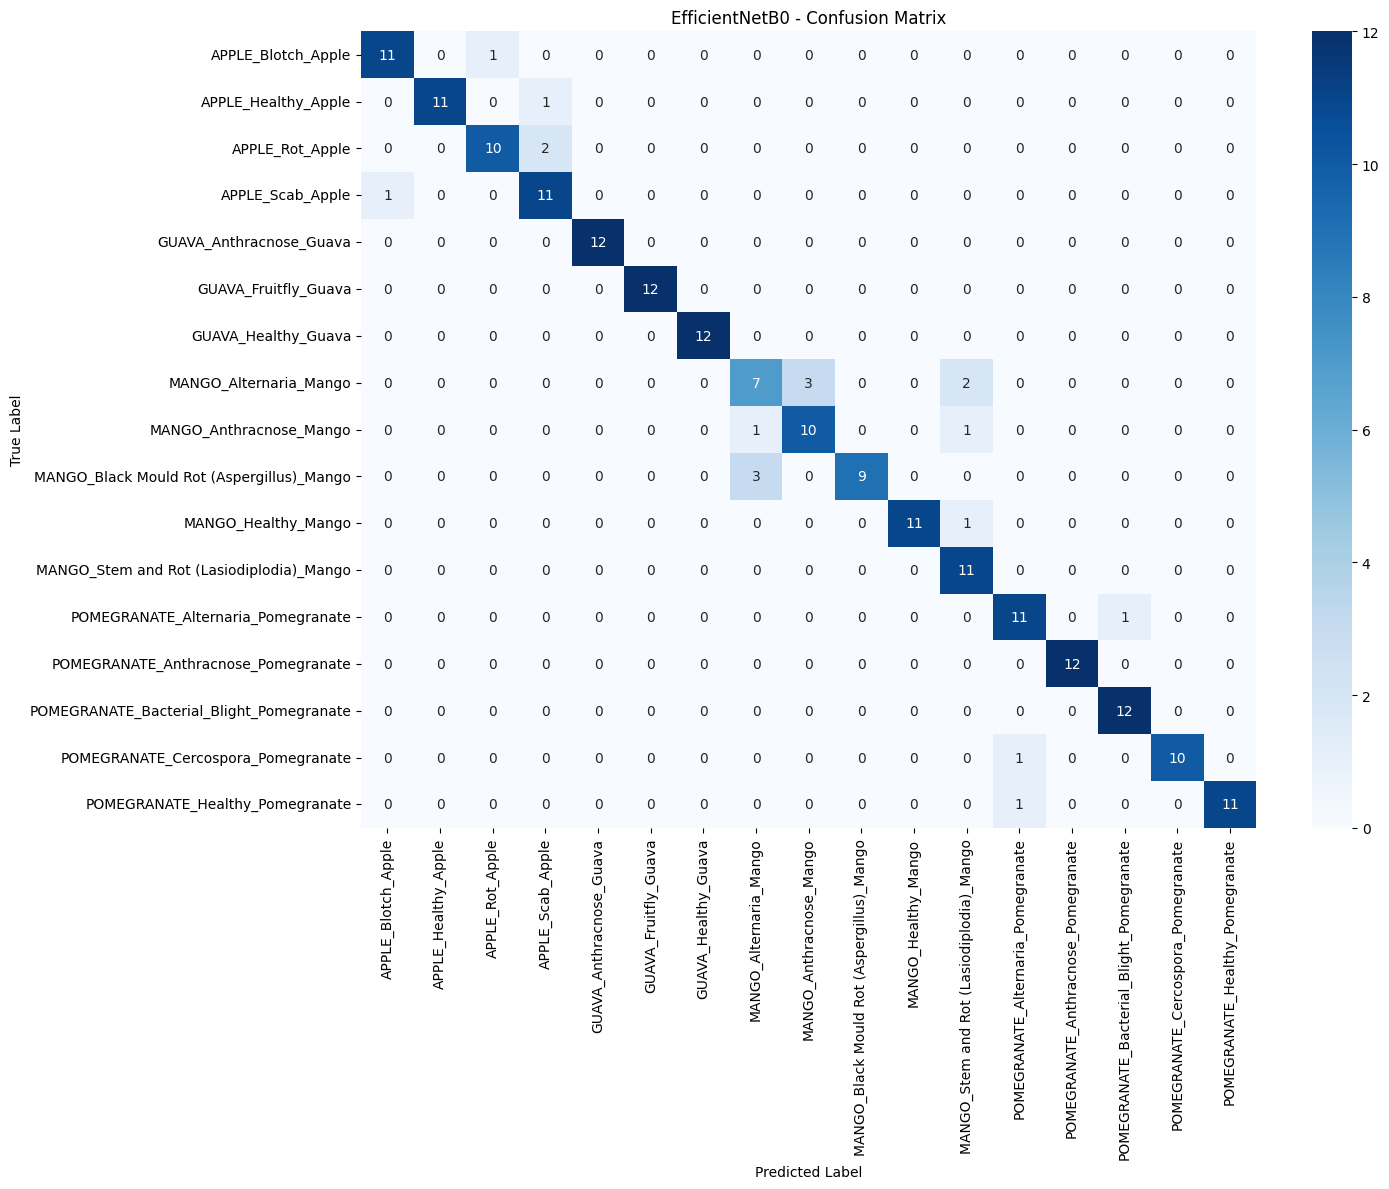

Final model saved as models/EfficientNetB0_final_finetuned.keras

==================== Training ResNet50 ====================

--- Phase 1: Training Head for ResNet50 ---
Epochs: 20, LR: 0.001
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 44s 977ms/step - accuracy: 0.8722 - loss: 0.3724 - val_accuracy: 0.7960 - val_loss: 0.5752 - learning_rate: 0.0010
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 809ms/step - accuracy: 0.8665 - loss: 0.4296 - val_accuracy: 0.8955 - val_loss: 0.2864 - learning_rate: 0.0010
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 792ms/step - accuracy: 0.9002 - loss: 0.2800 - val_accuracy: 0.8905 - val_loss: 0.3146 - learning_rate: 0.0010
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 772ms/step - accuracy: 0.8664 - loss: 0.3857 - val_accuracy: 0.9055 - val_loss: 0.2903 - learning_rate: 0.0010
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 656ms/step - accuracy: 0.8869 - loss: 0.3256
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 7

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_5           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 17)                  │           8,721 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,219,409 (100.02 MB)

 Trainable params: 14,721,041 (56.16 MB)

 Non-trainable params: 11,498,368 (43.86 MB)

Number of trainable parameters for fine-tuning: 14721041
Epoch 14/43
30/30 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.8584 - loss: 0.4221 - val_accuracy: 0.8955 - val_loss: 0.3862 - learning_rate: 1.0000e-04
Epoch 15/43
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 803ms/step - accuracy: 0.9252 - loss: 0.2034 - val_accuracy: 0.8806 - val_loss: 0.4677 - learning_rate: 1.0000e-04
Epoch 16/43
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 778ms/step - accuracy: 0.9561 - loss: 0.1456 - val_accuracy: 0.8856 - val_loss: 0.4252 - learning_rate: 1.0000e-04
Epoch 17/43
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 781ms/step - accuracy: 0.9604 - loss: 0.1223 - val_accuracy: 0.8905 - val_loss: 0.4380 - learning_rate: 1.0000e-04
Epoch 18/43
30/30 ━━━━━━━━━━━━━━━━━━━━ 31s 835ms/step - accuracy: 0.9549 - loss: 0.1141 - val_accuracy: 0.9005 - val_loss: 0.3764 - learning_rate: 1.0000e-04
Epoch 19/43
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 794ms/step - accuracy: 0.9685 - loss: 0.0990 - val_accuracy: 0.8905 - val_loss: 0.4414 - learning_rate: 1.0000e-0

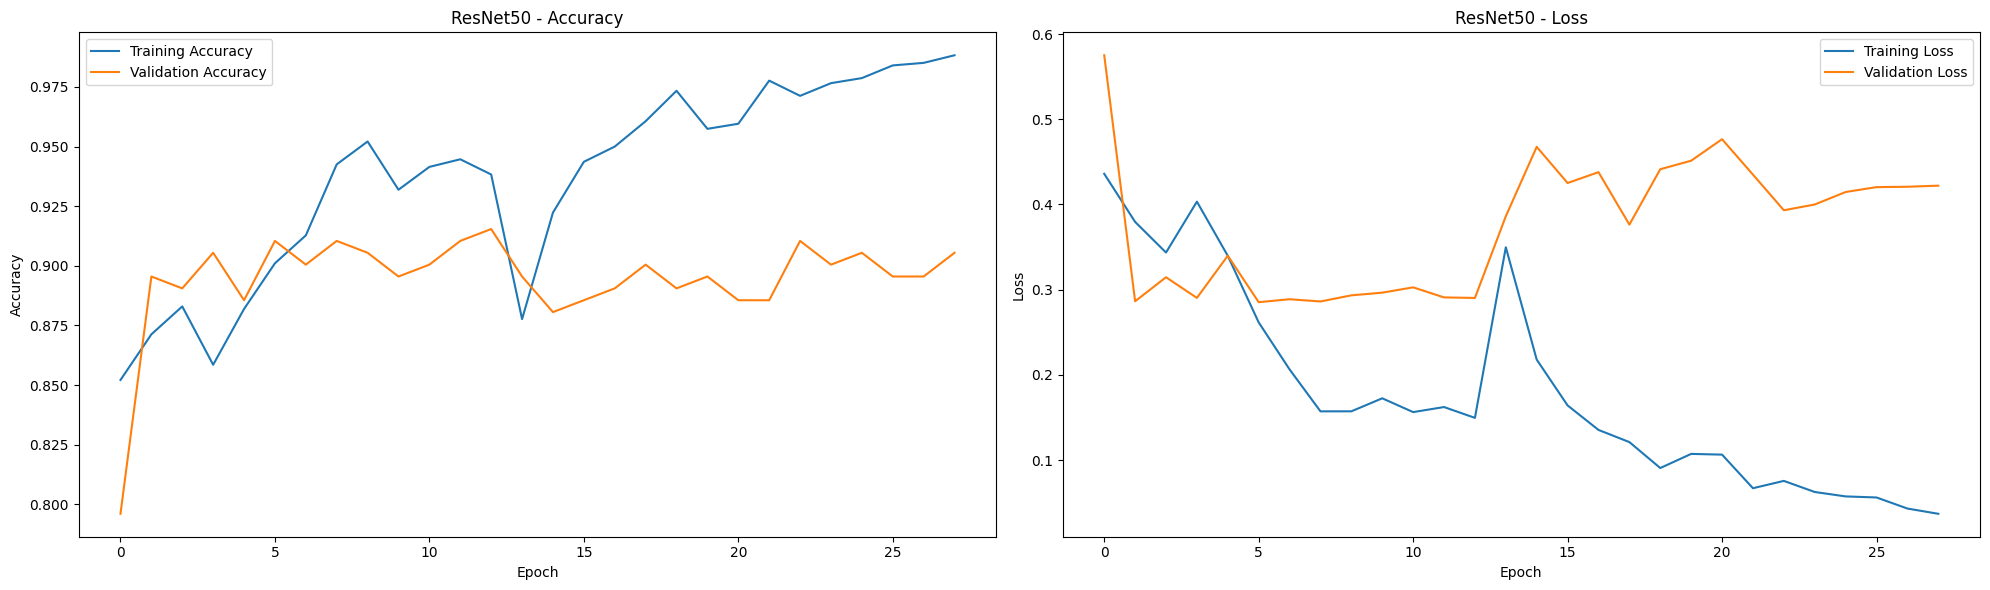


==================== Evaluating ResNet50 ====================
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 729ms/step - accuracy: 0.8690 - loss: 0.5668
Test accuracy: 0.8861
Test loss: 0.5206
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


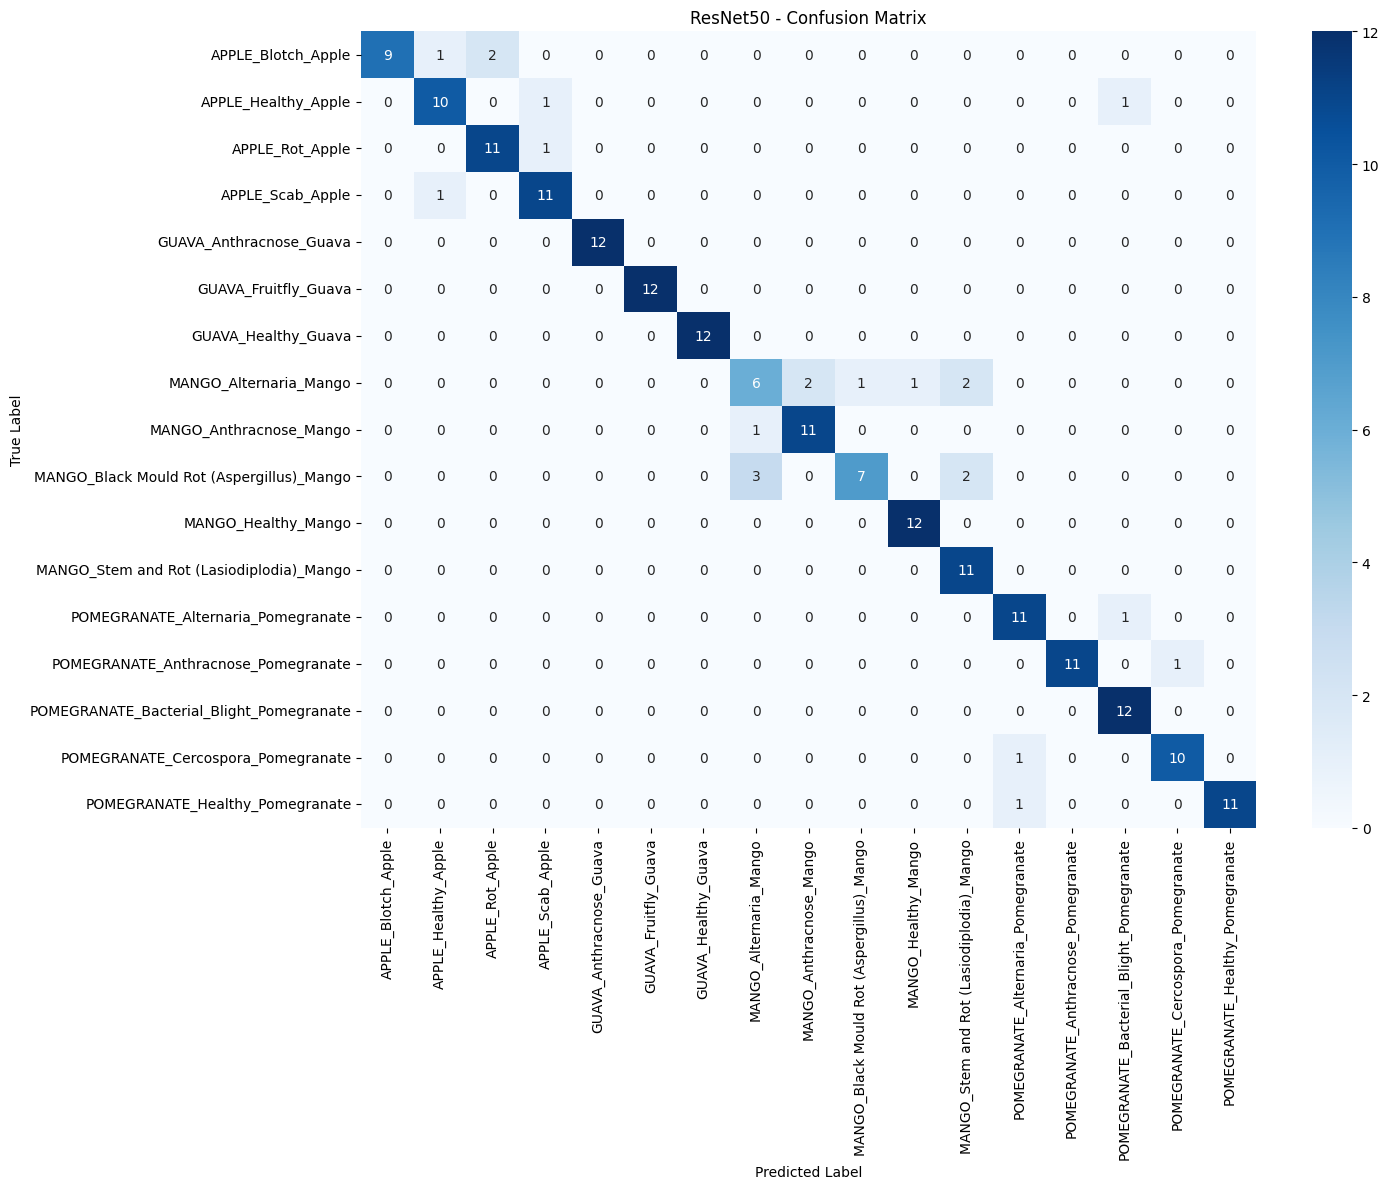

Final model saved as models/ResNet50_final_finetuned.keras

==================== Training & Evaluation Complete ====================


In [19]:
# Dictionary to store results
model_results = {}
model_histories = {} # Also store histories
INITIAL_EPOCHS = 20
INITIAL_LEARNING_RATE = 0.0010
# --- Training and Evaluation Loop ---
for model_name, model in models_to_train.items():
    print(f"\n==================== Training {model_name} ====================")

    if model_name == 'Custom_CNN':
        # Train Custom CNN normally (no fine-tuning)
        # Use slightly more epochs than initial transfer learning phase
        trained_model, history = train_model(
            model,
            model_name,
            train_generator,
            validation_generator,
            epochs=INITIAL_EPOCHS + 5, # e.g., 20 epochs for CNN
            learning_rate=INITIAL_LEARNING_RATE # Use initial LR
        )
    elif model_name in base_models:
         # Train transfer learning models with fine-tuning
         base_model = base_models[model_name]
         trained_model, history = train_model_with_finetuning(
             model,
             base_model, # Pass the base model reference
             model_name,
             train_generator,
             validation_generator,
             initial_epochs=INITIAL_EPOCHS,
             fine_tune_epochs=FINE_TUNE_EPOCHS,
             initial_lr=INITIAL_LEARNING_RATE,
             fine_tune_lr=FINE_TUNE_LEARNING_RATE,
             fine_tune_at_percentage=FINE_TUNE_AT_PERCENTAGE
         )
    else:
        print(f"Skipping {model_name} - Model type not recognized for training function.")
        continue

    model_histories[model_name] = history # Store history object

    # Plot training history
    print(f"\n--- Plotting Training History for {model_name} ---")
    plot_training_history(history, model_name)

    # Evaluate the final (best fine-tuned or best regular) model
    print(f"\n==================== Evaluating {model_name} ====================")
    # Ensure the best weights (either phase1/finetune best) are loaded before evaluation
    # train_model and train_model_with_finetuning should already restore best weights from EarlyStopping/Checkpoint
    test_acc, report, cm = evaluate_model(trained_model, test_generator)

    # Plot confusion matrix
    plot_confusion_matrix(cm, class_names, model_name) # Use class_names derived from generator

    # Store results
    model_results[model_name] = {
        'accuracy': test_acc,
        'report': report,
        'confusion_matrix': cm, # Store CM too if needed
        'model': trained_model,  # Store the final trained model object
        'history': history.history # Store the raw history data
    }

    # Save the FINAL model (already contains best weights loaded from checkpoint)
    final_model_path = f"models/{model_name}_final_finetuned.keras" if model_name != 'Custom_CNN' else f"models/{model_name}_final.keras"
    trained_model.save(final_model_path)
    print(f"Final model saved as {final_model_path}")


print("\n==================== Training & Evaluation Complete ====================")

In [20]:
def convert_to_tflite(model, model_name):
    """Convert the model to TFLite format"""
    # Convert the model to TFLite format
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    
    # Save the model
    tflite_file = f"models/{model_name}_model.tflite"
    with open(tflite_file, 'wb') as f:
        f.write(tflite_model)
    
    print(f"TFLite model saved to {tflite_file}")
    
    # Check the size of the model
    tflite_size = os.path.getsize(tflite_file) / (1024 * 1024)
    print(f"TFLite model size: {tflite_size:.2f} MB")
    
    return tflite_file

# Get the best model
best_model = model_results[best_model_name]['model']

# Convert to TFLite
tflite_model_path = convert_to_tflite(best_model, best_model_name)

Saved artifact at '/tmp/tmpczgyfsmu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1004')
Output Type:
  TensorSpec(shape=(None, 17), dtype=tf.float32, name=None)
Captures:
  134819334513312: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  134819339966544: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  134822716623328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716630720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716632656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716621040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716625616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716625792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716755280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134822716757568: TensorSpec(shape=(), dtype=tf.resource, nam

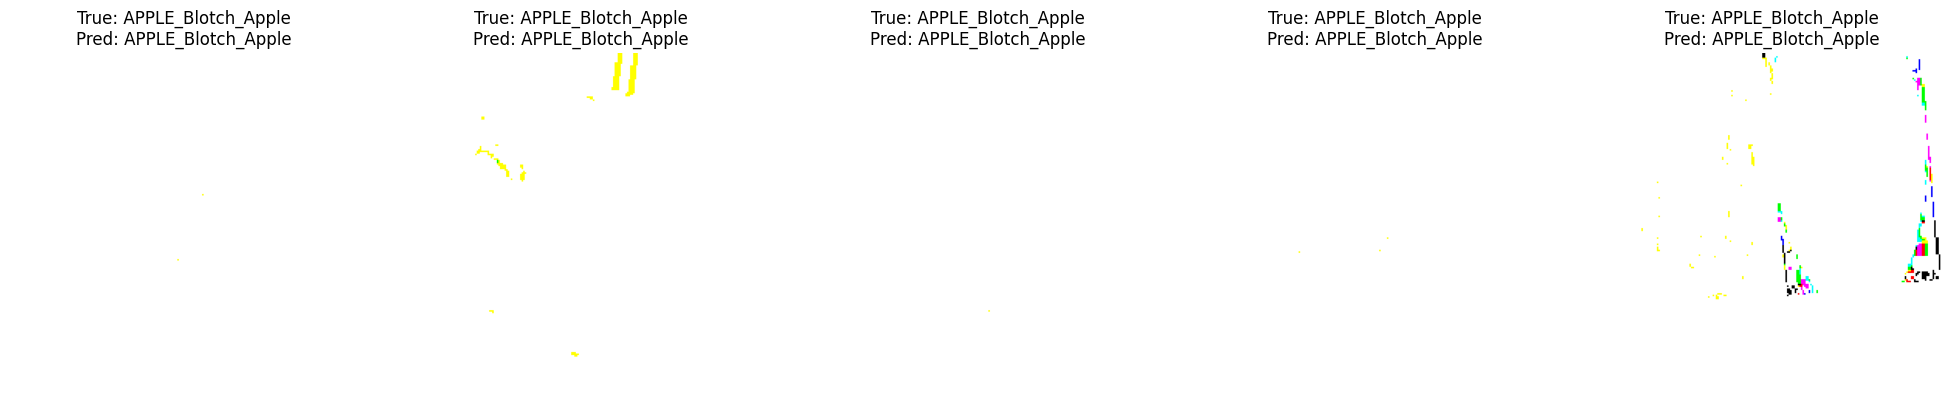

In [21]:
def test_tflite_model(tflite_model_path, test_generator, num_test_samples=5):
    """Test the TFLite model on a few samples"""
    # Load the TFLite model
    interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
    interpreter.allocate_tensors()
    
    # Get input and output tensors
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    
    # Get class names
    class_names = list(test_generator.class_indices.keys())
    reverse_class_map = {v: k for k, v in test_generator.class_indices.items()}
    
    # Reset the generator
    test_generator.reset()
    
    # Get some test images
    test_images = []
    test_labels = []
    
    batch_index = 0
    for x, y in test_generator:
        for i in range(len(x)):
            test_images.append(x[i])
            test_labels.append(np.argmax(y[i]))
        
        batch_index += 1
        if len(test_images) >= num_test_samples:
            break
    
    # Trim to the requested number of samples
    test_images = test_images[:num_test_samples]
    test_labels = test_labels[:num_test_samples]
    
    # Test the model
    fig, axes = plt.subplots(1, num_test_samples, figsize=(20, 4))
    
    for i, (img, true_label) in enumerate(zip(test_images, test_labels)):
        # Prepare the input
        input_data = np.expand_dims(img, axis=0).astype(np.float32)
        
        # Set the input tensor
        interpreter.set_tensor(input_details[0]['index'], input_data)
        
        # Run inference
        interpreter.invoke()
        
        # Get the output tensor
        output_data = interpreter.get_tensor(output_details[0]['index'])
        predicted_label = np.argmax(output_data)
        
        # Display the result
        ax = axes[i]
        ax.imshow(img)
        ax.set_title(f"True: {reverse_class_map[true_label]}\nPred: {reverse_class_map[predicted_label]}")
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()

# Test the TFLite model
test_tflite_model(tflite_model_path, test_generator, num_test_samples=5)

In [22]:
def create_tflite_with_metadata(tflite_model_path, class_names):
    """Add metadata to the TFLite model"""
    # Load the TFLite model
    with open(tflite_model_path, 'rb') as f:
        tflite_model = f.read()
    
    # Create a labels file
    labels_file = tflite_model_path.replace('.tflite', '_labels.txt')
    with open(labels_file, 'w') as f:
        for class_name in class_names:
            f.write(f"{class_name}\n")
    
    # Create metadata for the TFLite model
    try:
        from tflite_support import metadata as tflite_metadata
        from tflite_support import metadata_schema_py_generated as schema_fb
        
        # Create metadata
        model_meta = tflite_metadata.Metadata()
        
        # Add input metadata
        input_meta = tflite_metadata.InputMetadata()
        input_meta.name = "image"
        input_meta.description = "Input image to be classified."
        input_meta.content.contentProperties.colorSpace = schema_fb.ColorSpaceType.RGB
        input_meta.content.contentProperties.contentType = schema_fb.ContentPropertiesType.Image
        input_meta.content.contentPropertiesType = schema_fb.ContentProperties.ImageProperties
        input_meta.processUnits = [
            schema_fb.ProcessUnit(
                optionsType=schema_fb.ProcessUnitOptions.NormalizationOptions,
                options=schema_fb.NormalizationOptions(mean=[127.5], std=[127.5])
            )
        ]
        model_meta.inputMetadata = [input_meta]
        
        # Add output metadata
        output_meta = tflite_metadata.OutputMetadata()
        output_meta.name = "probability"
        output_meta.description = "Probabilities of the classes."
        label_file = tflite_metadata.AssociatedFile(
            type=schema_fb.AssociatedFileType.TENSOR_AXIS_LABELS,
            path=os.path.basename(labels_file)
        )
        output_meta.associatedFiles = [label_file]
        model_meta.outputMetadata = [output_meta]
        
        # Create the metadata
        metadata_buffer = model_meta.serialize()
        
        # Create the model with metadata
        tflite_model_with_metadata = tflite_metadata.populate_metadata_buffer(tflite_model, metadata_buffer)
        
        # Save the model
        model_with_metadata_path = tflite_model_path.replace('.tflite', '_with_metadata.tflite')
        with open(model_with_metadata_path, 'wb') as f:
            f.write(tflite_model_with_metadata)
        
        print(f"TFLite model with metadata saved to {model_with_metadata_path}")
        return model_with_metadata_path
    
    except ImportError:
        print("tflite-support library not found. Skipping metadata creation.")
        print("You can install it using pip install tflite-support")
        return tflite_model_path

# Get class names from the generator
class_names = list(test_generator.class_indices.keys())

# Add metadata to the TFLite model
try:
    final_tflite_model_path = create_tflite_with_metadata(tflite_model_path, class_names)
except Exception as e:
    print(f"Error adding metadata: {e}")
    final_tflite_model_path = tflite_model_path

print(f"\nFinal TFLite model path: {final_tflite_model_path}")
print("Class mapping:")
for idx, class_name in enumerate(class_names):
    print(f"  {idx}: {class_name}")

tflite-support library not found. Skipping metadata creation.
You can install it using pip install tflite-support

Final TFLite model path: models/EfficientNetB0_model.tflite
Class mapping:
  0: APPLE_Blotch_Apple
  1: APPLE_Healthy_Apple
  2: APPLE_Rot_Apple
  3: APPLE_Scab_Apple
  4: GUAVA_Anthracnose_Guava
  5: GUAVA_Fruitfly_Guava
  6: GUAVA_Healthy_Guava
  7: MANGO_Alternaria_Mango
  8: MANGO_Anthracnose_Mango
  9: MANGO_Black Mould Rot (Aspergillus)_Mango
  10: MANGO_Healthy_Mango
  11: MANGO_Stem and Rot (Lasiodiplodia)_Mango
  12: POMEGRANATE_Alternaria_Pomegranate
  13: POMEGRANATE_Anthracnose_Pomegranate
  14: POMEGRANATE_Bacterial_Blight_Pomegranate
  15: POMEGRANATE_Cercospora_Pomegranate
  16: POMEGRANATE_Healthy_Pomegranate


In [23]:
# Print summary of the best model and final artifacts
print("\n====== Fruit Disease Detection Model Summary ======")
print(f"Best model: {best_model_name}")
print(f"Test accuracy: {model_accuracies[best_model_name]:.4f}")
print(f"Average F1-score: {model_f1_scores[best_model_name]:.4f}")
print(f"\nModel files created:")
print(f"  - H5 Model: models/{best_model_name}_final.keras")
print(f"  - TFLite Model: {final_tflite_model_path}")

# Display final recommendations
print("\nRecommendations:")
print("1. For deployment on mobile devices, use the TFLite model")
print("2. For further improvement, consider:")
print("   - Collecting more training data, especially for classes with lower accuracy")
print("   - Fine-tuning the best model with unfrozen layers")
print("   - Experimenting with more advanced data augmentation")
print("   - Implementing ensemble methods by combining multiple models")

# Display note about using the TFLite model
print("\nTo use the TFLite model in an Android or iOS app:")
print("1. Load the model using TensorFlow Lite interpreter")
print("2. Preprocess images to match the expected input (224x224 RGB, normalized pixels)")
print("3. Run the model and get prediction results")
print("4. Map the output index to class names using the provided mapping")


====== Fruit Disease Detection Model Summary ======
Best model: EfficientNetB0
Test accuracy: 0.8861
Average F1-score: 0.8848

Model files created:
  - H5 Model: models/EfficientNetB0_final.keras
  - TFLite Model: models/EfficientNetB0_model.tflite

Recommendations:
1. For deployment on mobile devices, use the TFLite model
2. For further improvement, consider:
   - Collecting more training data, especially for classes with lower accuracy
   - Fine-tuning the best model with unfrozen layers
   - Experimenting with more advanced data augmentation
   - Implementing ensemble methods by combining multiple models

To use the TFLite model in an Android or iOS app:
1. Load the model using TensorFlow Lite interpreter
2. Preprocess images to match the expected input (224x224 RGB, normalized pixels)
3. Run the model and get prediction results
4. Map the output index to class names using the provided mapping
